[L2] objective stage 1: Inversion_results_120_120_padding_ext_10hz\L2_smooth\Inv_pml_kernel_2\objective_history.npy
[L2] objective con L2 : Inversion_results_120_120_padding_ext_10hz\L2_smooth_con_L2\Inv_pml_kernel_2\objective_history.npy
[L2] stage-1 model indices: 0 ... 80
[L2] con-L2 model indices : 0 ... 20
[COT] objective stage 1: Inversion_results_120_120_padding_ext_10hz\COT_smooth\Inv_pml_kernel_2\objective_history.npy
[COT] objective con L2 : Inversion_results_120_120_padding_ext_10hz\COT_smooth_con_L2\Inv_pml_kernel_2\objective_history.npy
[COT] stage-1 model indices: 0 ... 80
[COT] con-L2 model indices : 0 ... 20
[ROT] objective stage 1: Inversion_results_120_120_padding_ext_10hz\ROT_corrected_smooth\Inv_pml_kernel_2\objective_history.npy
[ROT] objective con L2 : Inversion_results_120_120_padding_ext_10hz\ROT_corrected_smooth_con_L2\Inv_pml_kernel_2\objective_history.npy
[ROT] stage-1 model indices: 0 ... 80
[ROT] con-L2 model indices : 0 ... 20

Figures saved to: C:\Users\h

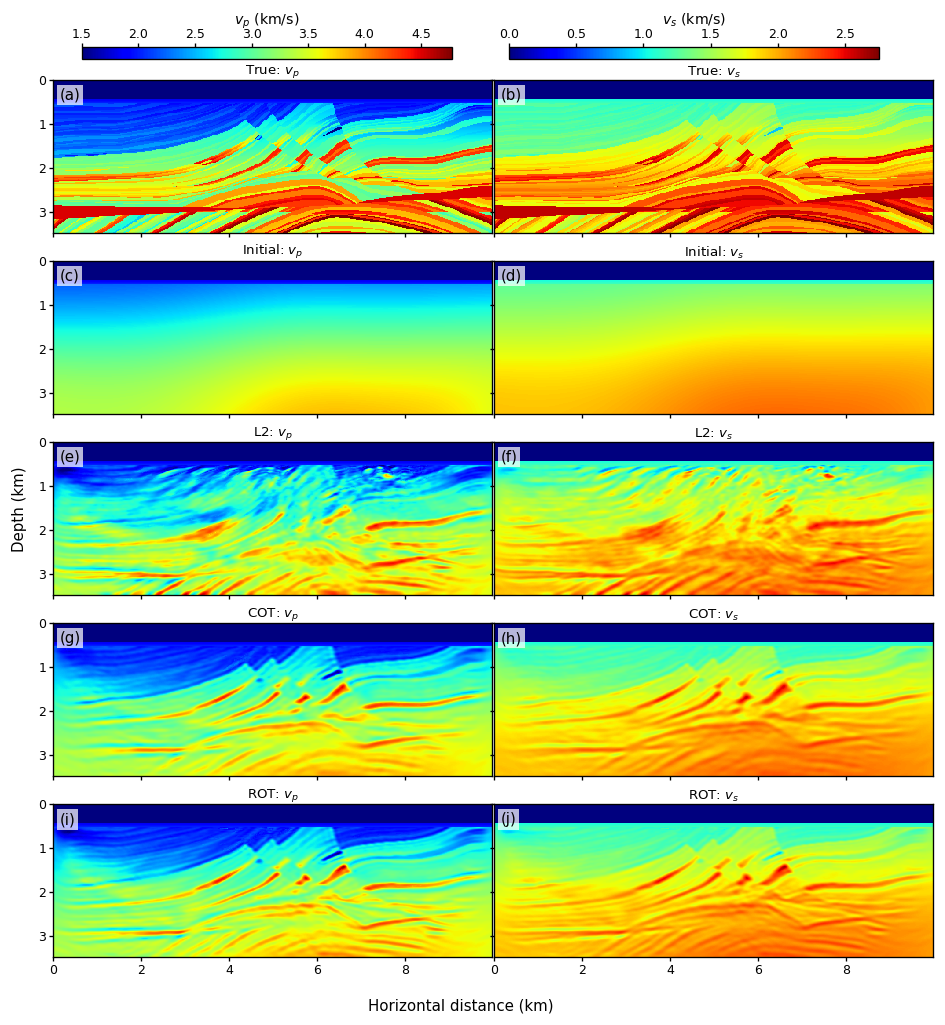

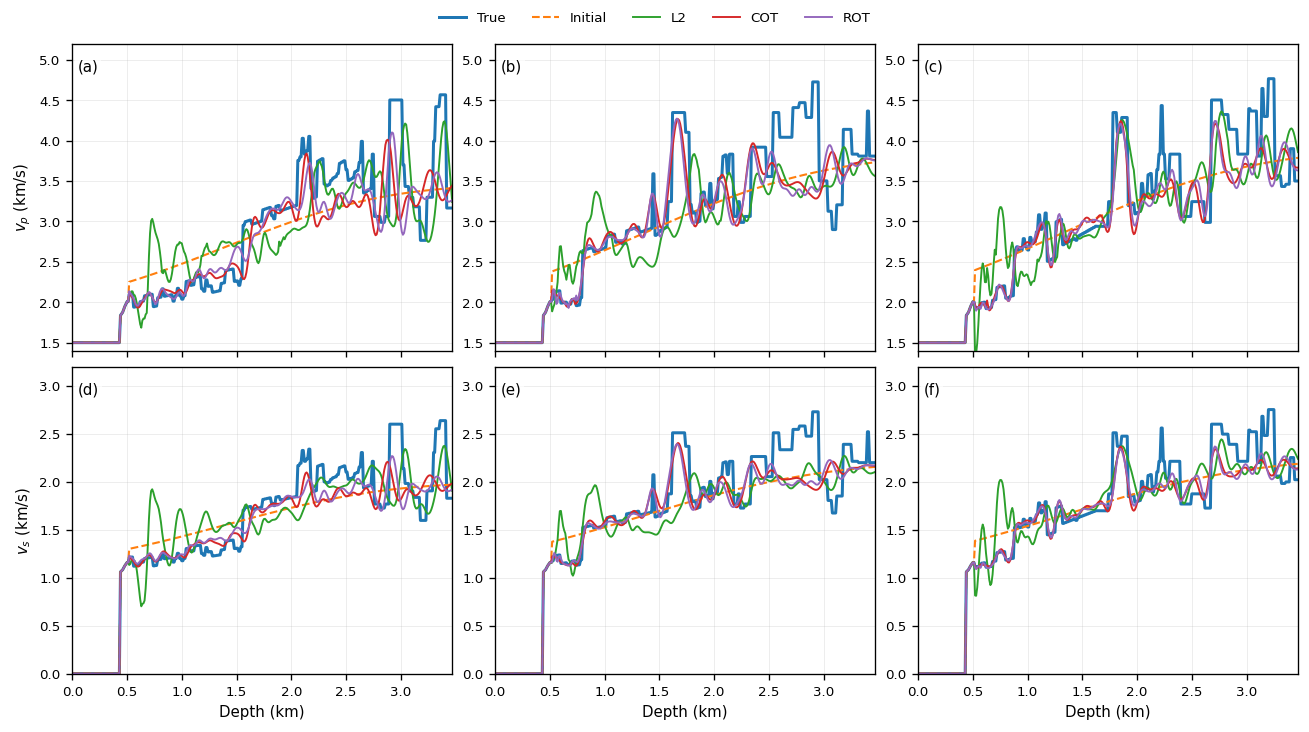

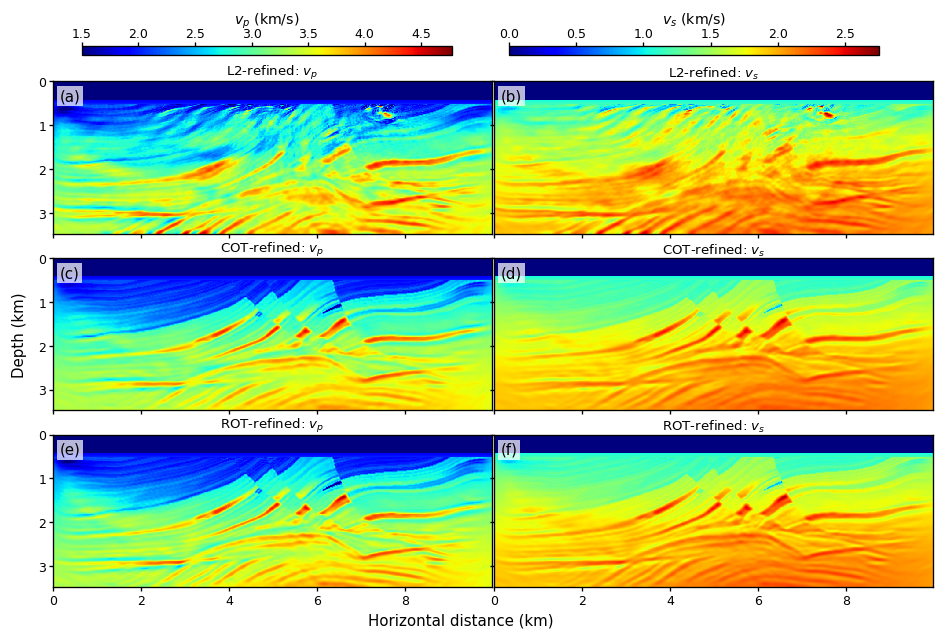

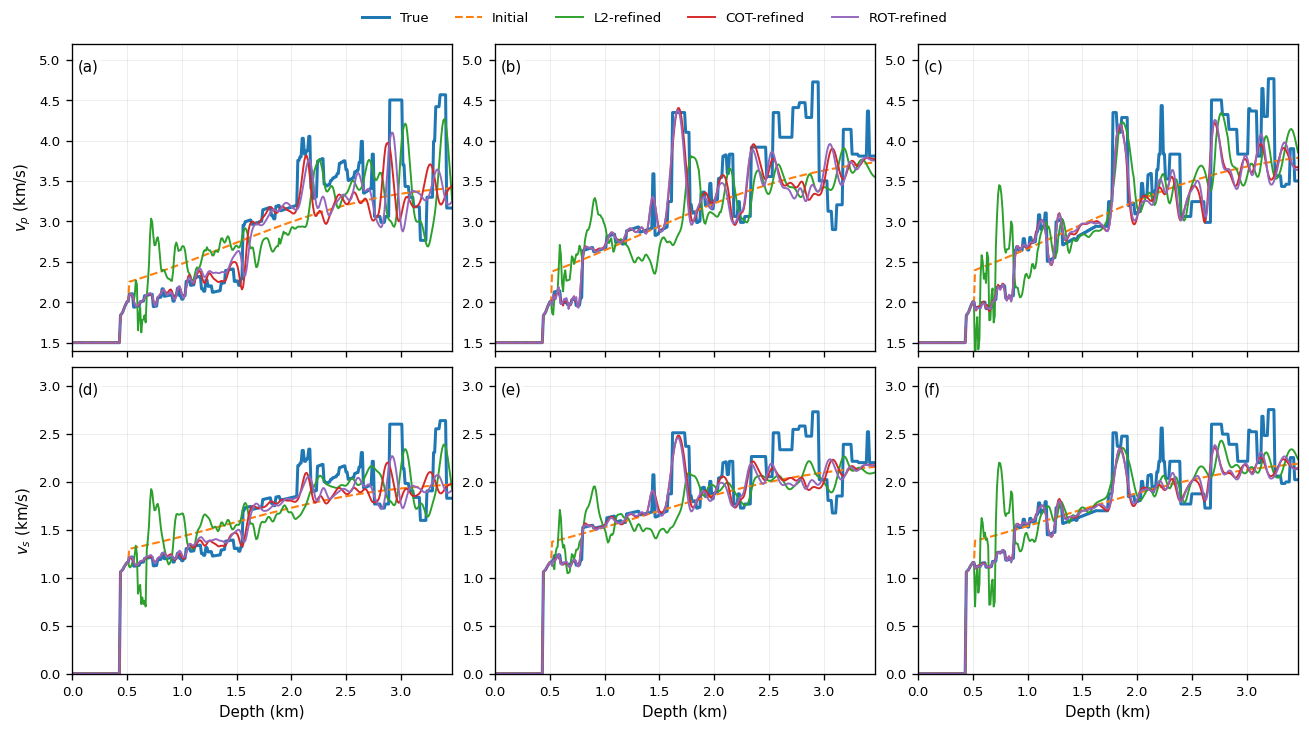

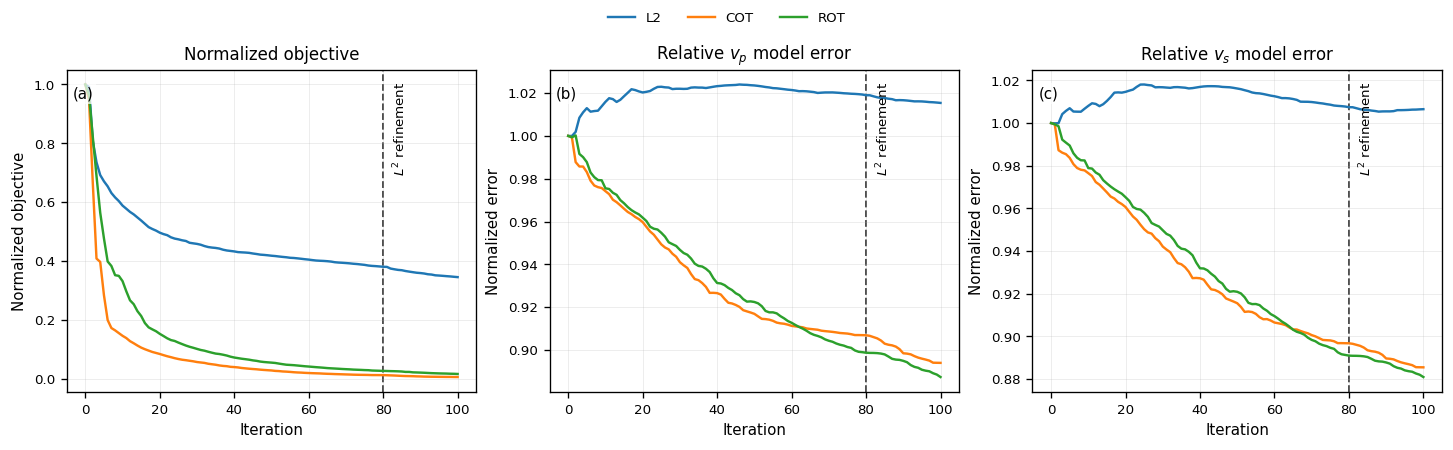

In [ ]:
"""
Marmousi inversion visualization
"""

from __future__ import annotations

import re
from pathlib import Path
from typing import Dict, Iterable, List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D


# =============================================================================
# User configuration
# =============================================================================

# Put this script in C:/Users/heyuxuan/Desktop/Model_1200 and keep ROOT=".".
ROOT = Path(".")

TRUE_DIR = ROOT / "Model_1200"
INITIAL_DIR = ROOT / "Initial_models" / "Initial_120_120_padding_1200"
RESULTS_DIR = ROOT / "Inversion_results_120_120_padding_ext_10hz"

RUN_DIRS = {
    "L2": RESULTS_DIR / "L2_smooth" / "Inv_pml_kernel_2",
    "COT": RESULTS_DIR / "COT_smooth" / "Inv_pml_kernel_2",
    "ROT": RESULTS_DIR / "ROT_corrected_smooth" / "Inv_pml_kernel_2",
}

refinement_DIRS = {
    "L2": RESULTS_DIR / "L2_smooth_con_L2" / "Inv_pml_kernel_2",
    "COT": RESULTS_DIR / "COT_smooth_con_L2" / "Inv_pml_kernel_2",
    "ROT": RESULTS_DIR / "ROT_corrected_smooth_con_L2" / "Inv_pml_kernel_2",
}

OUTPUT_DIR = ROOT / "marmousi_figures_new_corrected"

DX_M = 10.0
DZ_M = 10.0
CROP_LEFT = 100
CROP_RIGHT = 100

# False: cropped display starts from x=0 km.
# True: x-axis retains the original coordinate, so it starts from 1.30 km.
KEEP_ORIGINAL_X_COORD = False

SAVE_FIGURES = True
SHOW_FIGURES = True
DPI = 300

# True gives a visually continuous curve across the criterion switch:
# the refinement L2 history is multiplied so that its first value matches
# the last value of the first 80-step history.
#
# False normalizes each stage independently; the refinement starts at 1.
STITCH_OBJECTIVE_FOR_DISPLAY = True

# Shared color limits between all panels of the same parameter.
# None means infer limits from the cropped true model.
VP_CLIM = None  # example: (1.45, 5.5)
VS_CLIM = None  # example: (0.0, 3.2)

# Profile-plot value ranges (y-axis after switching to depth on x-axis).
# Set to None if you prefer matplotlib autoscaling.
VP_PROFILE_YLIM = (1.4, 5.2)
VS_PROFILE_YLIM = (0.0, 3.2)

METHODS = ("L2", "COT", "ROT")
ROW_NAMES = ("True", "Initial", "L2", "COT", "ROT")

# Matplotlib defaults selected to match the earlier paper figures.
plt.rcParams.update(
    {
        "font.size": 9,
        "axes.labelsize": 9,
        "axes.titlesize": 10,
        "legend.fontsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "figure.dpi": 120,
        "savefig.bbox": "tight",
    }
)


# =============================================================================
# Loading and file discovery
# =============================================================================

def load_array(path: Path) -> np.ndarray:
    """Load a numeric NumPy array and remove trivial singleton dimensions."""
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")
    arr = np.asarray(np.load(path)).squeeze()
    if arr.ndim != 2:
        raise ValueError(f"Expected a 2-D model at {path}, got shape {arr.shape}")
    return arr


def crop_x(data: np.ndarray) -> np.ndarray:
    """Remove the left and right padding along the first (horizontal) axis."""
    if data.ndim != 2:
        raise ValueError(f"crop_x expects a 2-D array, got {data.shape}")
    nx = data.shape[0]
    if CROP_LEFT + CROP_RIGHT >= nx:
        raise ValueError(
            f"Cropping [{CROP_LEFT}:{nx - CROP_RIGHT}] is invalid for nx={nx}"
        )
    right = nx - CROP_RIGHT if CROP_RIGHT > 0 else nx
    return data[CROP_LEFT:right, :]


def load_final_model(run_dir: Path, parameter: str) -> np.ndarray:
    """
    Load final/vp.npy or final/vs.npy.

    A recursive fallback is included in case the output has one extra directory
    level, but ambiguous matches raise an error rather than silently guessing.
    """
    direct = run_dir / "final" / f"{parameter}.npy"
    if direct.exists():
        return load_array(direct)

    matches = sorted(run_dir.rglob(f"{parameter}.npy"))
    final_matches = [p for p in matches if p.parent.name.lower() == "final"]
    if len(final_matches) == 1:
        return load_array(final_matches[0])
    if len(final_matches) > 1:
        raise RuntimeError(
            f"Ambiguous final {parameter} files in {run_dir}:\n"
            + "\n".join(map(str, final_matches))
        )
    raise FileNotFoundError(f"Could not find final/{parameter}.npy below {run_dir}")


def _iteration_number(path: Path) -> int | None:
    """Extract the integer in an iter_0007-like path or filename."""
    for part in reversed(path.parts):
        match = re.search(r"iter[_-]?(\d+)", part, flags=re.IGNORECASE)
        if match:
            return int(match.group(1))
    return None


def discover_iteration_models(
    run_dir: Path, parameter: str
) -> List[Tuple[int, Path]]:
    """
    Discover iteration models robustly.

    Supported examples:
      iter_0007/vp.npy
      iter_0007_vp.npy
      iteration-0007-vp.npy
    """
    candidates = sorted(run_dir.rglob("*.npy"))
    selected: Dict[int, Path] = {}

    for path in candidates:
        name = path.name.lower()
        parent = path.parent.name.lower()

        parameter_match = (
            name == f"{parameter}.npy"
            or re.search(rf"(^|[_-]){parameter}([_.-]|$)", name) is not None
        )
        if not parameter_match:
            continue

        iteration = _iteration_number(path)
        if iteration is None:
            continue

        # Prefer an exact parameter filename inside an iteration directory.
        quality = int(name == f"{parameter}.npy") + int("iter" in parent)
        previous = selected.get(iteration)
        if previous is None:
            selected[iteration] = path
        else:
            previous_quality = (
                int(previous.name.lower() == f"{parameter}.npy")
                + int("iter" in previous.parent.name.lower())
            )
            if quality > previous_quality:
                selected[iteration] = path

    if not selected:
        raise FileNotFoundError(
            f"No iteration {parameter} models were found below {run_dir}"
        )

    return sorted(selected.items(), key=lambda item: item[0])


def load_iteration_sequence(run_dir: Path, parameter: str) -> Tuple[np.ndarray, List[int]]:
    """Return model sequence with shape (n_iterations, nx, nz)."""
    discovered = discover_iteration_models(run_dir, parameter)
    numbers = [number for number, _ in discovered]
    models = [load_array(path) for _, path in discovered]

    shape0 = models[0].shape
    for number, model in zip(numbers, models):
        if model.shape != shape0:
            raise ValueError(
                f"Inconsistent model shape at iteration {number}: "
                f"{model.shape} versus {shape0}"
            )
    return np.stack(models, axis=0), numbers


def load_numeric_history(path: Path) -> np.ndarray:
    """Load a 1-D numeric history from .npy, .npz, .txt, .dat, or .csv."""
    suffix = path.suffix.lower()
    if suffix == ".npy":
        arr = np.load(path)
    elif suffix == ".npz":
        archive = np.load(path)
        keys = list(archive.keys())
        if len(keys) != 1:
            raise ValueError(f"Ambiguous arrays in {path}: {keys}")
        arr = archive[keys[0]]
    else:
        arr = np.loadtxt(path)

    arr = np.asarray(arr, dtype=float).squeeze()
    if arr.ndim == 0:
        arr = arr.reshape(1)
    if arr.ndim > 1:
        # Common formats are (n,1), (1,n), or [iteration, objective].
        if arr.shape[1] == 2:
            arr = arr[:, 1]
        else:
            arr = arr.reshape(-1)
    return arr[np.isfinite(arr)]


def discover_objective_history(run_dir: Path) -> Tuple[np.ndarray, Path]:
    """
    Find the most plausible objective-history file below run_dir.

    Files containing 'objective' are ranked above files containing 'loss'.
    A longer 1-D sequence is preferred over a scalar.
    """
    supported = {".npy", ".npz", ".txt", ".dat", ".csv"}
    candidates = [
        p
        for p in run_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in supported
        and ("objective" in p.name.lower() or "loss" in p.name.lower())
        and "scaling" not in p.name.lower()
    ]

    ranked: List[Tuple[Tuple[int, int, int], np.ndarray, Path]] = []
    for path in candidates:
        try:
            history = load_numeric_history(path)
        except Exception:
            continue
        if history.size == 0:
            continue

        name = path.name.lower()
        score = (
            int("history" in name),
            int("objective" in name),
            int(history.size),
        )
        ranked.append((score, history, path))

    if not ranked:
        raise FileNotFoundError(
            f"No readable objective/loss history was found below {run_dir}"
        )

    ranked.sort(key=lambda item: item[0], reverse=True)
    _, history, path = ranked[0]
    return history, path


# =============================================================================
# Coordinates, errors, and history concatenation
# =============================================================================

def model_extent_km(model_cropped: np.ndarray) -> Tuple[float, float, float, float]:
    """Extent for imshow(data.T, origin='upper')."""
    nx, nz = model_cropped.shape
    x0 = CROP_LEFT * DX_M / 1000.0 if KEEP_ORIGINAL_X_COORD else 0.0
    x1 = x0 + (nx - 1) * DX_M / 1000.0
    z1 = (nz - 1) * DZ_M / 1000.0
    return x0, x1, z1, 0.0


def depth_axis_km(model: np.ndarray) -> np.ndarray:
    return np.arange(model.shape[1]) * DZ_M / 1000.0


def horizontal_positions(nx_cropped: int) -> Tuple[List[int], List[float]]:
    """
    Indices nearest to one quarter, one half, and three quarters of the
    cropped horizontal model.
    """
    fractions = (0.25, 0.50, 0.75)
    indices = [int(round(f * (nx_cropped - 1))) for f in fractions]
    x0 = CROP_LEFT * DX_M / 1000.0 if KEEP_ORIGINAL_X_COORD else 0.0
    x_km = [x0 + index * DX_M / 1000.0 for index in indices]
    return indices, x_km


def relative_l2_error(model: np.ndarray, truth: np.ndarray) -> float:
    denominator = np.linalg.norm(truth.ravel())
    if denominator == 0:
        raise ZeroDivisionError("The true model has zero norm.")
    return np.linalg.norm((model - truth).ravel()) / denominator


def normalized_model_error_history(
    first_sequence: np.ndarray,
    refinement_sequence: np.ndarray,
    truth: np.ndarray,
) -> np.ndarray:
    """
    Concatenate cropped model errors.

    refinement_sequence[0] is dropped when it duplicates the final model of
    the first stage. All errors are normalized by the initial error, so each
    method starts at 1.
    """
    first_cropped = np.stack([crop_x(model) for model in first_sequence])
    refinement_cropped = np.stack([crop_x(model) for model in refinement_sequence])
    truth_cropped = crop_x(truth)

    first_errors = np.array(
        [relative_l2_error(model, truth_cropped) for model in first_cropped]
    )
    refinement_errors = np.array(
        [relative_l2_error(model, truth_cropped) for model in refinement_cropped]
    )

    if first_errors.size == 0:
        raise ValueError("Empty first-stage model sequence")

    # Drop the duplicated refinement starting model where appropriate.
    if refinement_errors.size:
        if np.allclose(
            first_cropped[-1],
            refinement_cropped[0],
            rtol=1e-6,
            atol=1e-7,
        ):
            refinement_errors = refinement_errors[1:]

    combined = np.concatenate([first_errors, refinement_errors])
    if combined[0] == 0:
        return combined
    return combined / combined[0]


def combine_objective_histories(
    first: np.ndarray,
    refinement: np.ndarray,
    stitch: bool,
) -> np.ndarray:
    """
    Combine histories across the switch to L2.

    This is a display-only normalization because the first-stage and
    refinement criteria are not generally the same for COT and ROT.
    """
    first = np.asarray(first, dtype=float)
    refinement = np.asarray(refinement, dtype=float)

    if first.size == 0:
        raise ValueError("Empty first-stage objective history")
    first_norm = first / first[0] if first[0] != 0 else first.copy()

    if refinement.size == 0:
        return first_norm

    refinement_norm = (
        refinement / refinement[0]
        if refinement[0] != 0
        else refinement.copy()
    )

    # The first refinement entry normally evaluates the same model as the
    # last first-stage entry, so it is not counted as an extra iteration.
    refinement_tail = refinement_norm[1:] if refinement_norm.size > 1 else np.empty(0)

    if stitch and refinement_tail.size:
        refinement_tail = refinement_tail * first_norm[-1]

    return np.concatenate([first_norm, refinement_tail])


# =============================================================================
# Plot helpers
# =============================================================================

def infer_clim(truth_cropped: np.ndarray, configured):
    if configured is not None:
        return tuple(configured)
    return float(np.nanmin(truth_cropped)), float(np.nanmax(truth_cropped))


def add_panel_label(ax: plt.Axes, label: str) -> None:
    ax.text(
        0.015,
        0.95,
        label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        color="black",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.72, pad=1.5),
    )


def save_figure(fig: plt.Figure, stem: str) -> None:
    if not SAVE_FIGURES:
        return
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=DPI)
    fig.savefig(OUTPUT_DIR / f"{stem}.pdf")


def style_profile_axis(ax: plt.Axes, col: int, row: int) -> None:
    ax.grid(alpha=0.22, linewidth=0.6)
    if row == 1:
        ax.set_xlabel("Velocity (km/s)")
    if col == 0:
        ax.set_ylabel("Depth (km)")
    ax.invert_yaxis()


# =============================================================================
# Figure 1: true, initial, and first-stage results
# =============================================================================

def plot_stage1_models(
    vp_models: Dict[str, np.ndarray],
    vs_models: Dict[str, np.ndarray],
) -> plt.Figure:
    """
    Compact 5 x 2 Marmousi model figure.

    Layout is intentionally matched to the accepted linear-model figure:
      - manual GridSpec
      - very small horizontal/vertical spacing
      - small panel titles
      - manually positioned top colorbars
      - one shared x label and one shared y label
    """
    panels = [
        [crop_x(vp_models["True"]),    crop_x(vs_models["True"])],
        [crop_x(vp_models["Initial"]), crop_x(vs_models["Initial"])],
        [crop_x(vp_models["L2"]),      crop_x(vs_models["L2"])],
        [crop_x(vp_models["COT"]),     crop_x(vs_models["COT"])],
        [crop_x(vp_models["ROT"]),     crop_x(vs_models["ROT"])],
    ]

    row_names = ["True", "Initial", "L2", "COT", "ROT"]
    parameter_names = [r"$v_p$", r"$v_s$"]

    vp_truth = panels[0][0]
    vs_truth = panels[0][1]

    vp_clim = infer_clim(vp_truth, VP_CLIM)
    vs_clim = infer_clim(vs_truth, VS_CLIM)
    clims = [vp_clim, vs_clim]

    extent = model_extent_km(vp_truth)

    panel_labels = [
        ["(a)", "(b)"],
        ["(c)", "(d)"],
        ["(e)", "(f)"],
        ["(g)", "(h)"],
        ["(i)", "(j)"],
    ]

    # Same compact aspect philosophy as the linear-model figure.
    fig = plt.figure(figsize=(8.0, 8.70))

    gs = fig.add_gridspec(
        5, 2,
        width_ratios=[1, 1],
        height_ratios=[1, 1, 1, 1, 1],
        wspace=0.005,
        hspace=0.090,
    )

    ims = [None, None]

    for i in range(5):
        for j in range(2):
            ax = fig.add_subplot(gs[i, j])

            im = ax.imshow(
                panels[i][j].T,
                cmap="jet",
                origin="upper",
                extent=extent,
                aspect="equal",
                vmin=clims[j][0],
                vmax=clims[j][1],
                interpolation="nearest",
            )
            ims[j] = im

            add_panel_label(ax, panel_labels[i][j])

            # Exactly the compact title styling used for the linear model.
            ax.set_title(
                rf"{row_names[i]}: {parameter_names[j]}",
                fontsize=8.0,
                pad=0.8,
            )

            ax.tick_params(
                axis="both",
                which="major",
                labelsize=7.5,
                length=2.5,
                pad=1.5,
            )

            # Only bottom row shows x tick labels.
            if i != 4:
                ax.tick_params(labelbottom=False)

            # Only left column shows y tick labels.
            if j != 0:
                ax.tick_params(labelleft=False)

    # Leave a little more room at the bottom than before so the shared
    # horizontal-distance label cannot overlap the bottom-row tick labels.
    fig.subplots_adjust(
        left=0.075,
        right=0.992,
        bottom=0.065,
        top=0.918,
    )

    # ============================================================
    # Manually placed top colorbars
    # ============================================================
    cax_vp = fig.add_axes([0.105, 0.932, 0.385, 0.011])
    cax_vs = fig.add_axes([0.550, 0.932, 0.385, 0.011])

    cbar_vp = fig.colorbar(
        ims[0],
        cax=cax_vp,
        orientation="horizontal",
    )
    cbar_vp.set_label(r"$v_p$ (km/s)", fontsize=8.5, labelpad=2)
    cbar_vp.ax.tick_params(labelsize=7.5, length=2.5, pad=1.0)
    cbar_vp.ax.xaxis.set_ticks_position("top")
    cbar_vp.ax.xaxis.set_label_position("top")

    cbar_vs = fig.colorbar(
        ims[1],
        cax=cax_vs,
        orientation="horizontal",
    )
    cbar_vs.set_label(r"$v_s$ (km/s)", fontsize=8.5, labelpad=2)
    cbar_vs.ax.tick_params(labelsize=7.5, length=2.5, pad=1.0)
    cbar_vs.ax.xaxis.set_ticks_position("top")
    cbar_vs.ax.xaxis.set_label_position("top")

    # ============================================================
    # Shared axis labels
    # ============================================================
    fig.text(
        0.50, 0.025,
        "Horizontal distance (km)",
        ha="center",
        va="center",
        fontsize=9,
    )

    fig.text(
        0.040, 0.50,
        "Depth (km)",
        ha="center",
        va="center",
        rotation="vertical",
        fontsize=9,
    )

    save_figure(fig, "marmousi_stage1_models_5x2_compact")
    return fig


# =============================================================================
# Figures 2 and 4: vertical profiles at x = 1/4, 1/2, 3/4
# =============================================================================

def plot_profiles(
    vp_models: Dict[str, np.ndarray],
    vs_models: Dict[str, np.ndarray],
    model_names: Sequence[str],
    stem: str,
) -> plt.Figure:
    true_cropped = crop_x(vp_models["True"])
    indices, x_positions = horizontal_positions(true_cropped.shape[0])
    depth = depth_axis_km(true_cropped)

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(10.8, 6.0),
        sharex=True,
        constrained_layout=True,
    )

    line_styles = {
        "True": dict(linestyle="-", linewidth=1.8),
        "Initial": dict(linestyle="--", linewidth=1.25),
        "L2": dict(linestyle="-", linewidth=1.15),
        "COT": dict(linestyle="-", linewidth=1.15),
        "ROT": dict(linestyle="-", linewidth=1.15),
        "L2-refined": dict(linestyle="-", linewidth=1.15),
        "COT-refined": dict(linestyle="-", linewidth=1.15),
        "ROT-refined": dict(linestyle="-", linewidth=1.15),
    }

    vp_ylim = VP_PROFILE_YLIM
    vs_ylim = VS_PROFILE_YLIM

    for col, (index, x_km) in enumerate(zip(indices, x_positions)):
        for name in model_names:
            vp = crop_x(vp_models[name])
            vs = crop_x(vs_models[name])

            axes[0, col].plot(
                depth,
                vp[index, :],
                label=name,
                **line_styles.get(name, {}),
            )
            axes[1, col].plot(
                depth,
                vs[index, :],
                label=name,
                **line_styles.get(name, {}),
            )

        axes[0, col].grid(alpha=0.22, linewidth=0.6)
        axes[1, col].grid(alpha=0.22, linewidth=0.6)

        axes[0, col].set_xlim(depth[0], depth[-1])
        axes[1, col].set_xlim(depth[0], depth[-1])

        if vp_ylim is not None:
            axes[0, col].set_ylim(*vp_ylim)
        if vs_ylim is not None:
            axes[1, col].set_ylim(*vs_ylim)

        add_panel_label(axes[0, col], f"({chr(97 + col)})")
        add_panel_label(axes[1, col], f"({chr(100 + col)})")

    for col in range(3):
        axes[1, col].set_xlabel("Depth (km)")

    axes[0, 0].set_ylabel(r"$v_p$ (km/s)")
    axes[1, 0].set_ylabel(r"$v_s$ (km/s)")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="outside upper center",
        ncol=len(model_names),
        frameon=False,
    )

    save_figure(fig, stem)
    return fig


# =============================================================================
# Figure 3: refinement results
# =============================================================================

def plot_refinement_models(
    vp_models: Dict[str, np.ndarray],
    vs_models: Dict[str, np.ndarray],
) -> plt.Figure:
    """
    Compact 3 x 2 refinement-result figure using the same layout conventions
    as the stage-1 and linear-model figures.
    """
    row_names = ["L2-refined", "COT-refined", "ROT-refined"]
    parameter_names = [r"$v_p$", r"$v_s$"]

    panels = [
        [crop_x(vp_models["L2-refined"]),  crop_x(vs_models["L2-refined"])],
        [crop_x(vp_models["COT-refined"]), crop_x(vs_models["COT-refined"])],
        [crop_x(vp_models["ROT-refined"]), crop_x(vs_models["ROT-refined"])],
    ]

    vp_truth = crop_x(vp_models["True"])
    vs_truth = crop_x(vs_models["True"])

    vp_clim = infer_clim(vp_truth, VP_CLIM)
    vs_clim = infer_clim(vs_truth, VS_CLIM)
    clims = [vp_clim, vs_clim]

    extent = model_extent_km(vp_truth)

    panel_labels = [
        ["(a)", "(b)"],
        ["(c)", "(d)"],
        ["(e)", "(f)"],
    ]

    fig = plt.figure(figsize=(8.0, 5.40))

    gs = fig.add_gridspec(
        3, 2,
        width_ratios=[1, 1],
        height_ratios=[1, 1, 1],
        wspace=0.005,
        hspace=0.115,
    )

    ims = [None, None]

    for i in range(3):
        for j in range(2):
            ax = fig.add_subplot(gs[i, j])

            im = ax.imshow(
                panels[i][j].T,
                cmap="jet",
                origin="upper",
                extent=extent,
                aspect="equal",
                vmin=clims[j][0],
                vmax=clims[j][1],
                interpolation="nearest",
            )
            ims[j] = im

            add_panel_label(ax, panel_labels[i][j])

            ax.set_title(
                rf"{row_names[i]}: {parameter_names[j]}",
                fontsize=8.0,
                pad=0.8,
            )

            ax.tick_params(
                axis="both",
                which="major",
                labelsize=7.5,
                length=2.5,
                pad=1.5,
            )

            if i != 2:
                ax.tick_params(labelbottom=False)

            if j != 0:
                ax.tick_params(labelleft=False)

    fig.subplots_adjust(
        left=0.075,
        right=0.992,
        bottom=0.085,
        top=0.875,
    )

    # Top horizontal colorbars
    cax_vp = fig.add_axes([0.105, 0.910, 0.385, 0.014])
    cax_vs = fig.add_axes([0.550, 0.910, 0.385, 0.014])

    cbar_vp = fig.colorbar(
        ims[0],
        cax=cax_vp,
        orientation="horizontal",
    )
    cbar_vp.set_label(r"$v_p$ (km/s)", fontsize=8.5, labelpad=2)
    cbar_vp.ax.tick_params(labelsize=7.5, length=2.5, pad=1.0)
    cbar_vp.ax.xaxis.set_ticks_position("top")
    cbar_vp.ax.xaxis.set_label_position("top")

    cbar_vs = fig.colorbar(
        ims[1],
        cax=cax_vs,
        orientation="horizontal",
    )
    cbar_vs.set_label(r"$v_s$ (km/s)", fontsize=8.5, labelpad=2)
    cbar_vs.ax.tick_params(labelsize=7.5, length=2.5, pad=1.0)
    cbar_vs.ax.xaxis.set_ticks_position("top")
    cbar_vs.ax.xaxis.set_label_position("top")

    fig.text(
        0.50, 0.038,
        "Horizontal distance (km)",
        ha="center",
        va="center",
        fontsize=9,
    )

    fig.text(
        0.040, 0.48,
        "Depth (km)",
        ha="center",
        va="center",
        rotation="vertical",
        fontsize=9,
    )

    save_figure(fig, "marmousi_refinement_models_3x2_compact")
    return fig


# =============================================================================
# Figure 5: objectives and model-error histories
# =============================================================================

def plot_convergence(
    objective_histories: Dict[str, np.ndarray],
    vp_errors: Dict[str, np.ndarray],
    vs_errors: Dict[str, np.ndarray],
    switch_iteration: int,
) -> plt.Figure:
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(12.0, 3.65),
        constrained_layout=True,
    )

    for method in METHODS:
        objective = objective_histories[method]
        axes[0].plot(
            np.arange(objective.size),
            objective,
            linewidth=1.45,
            label=method,
        )
        axes[1].plot(
            np.arange(vp_errors[method].size),
            vp_errors[method],
            linewidth=1.45,
            label=method,
        )
        axes[2].plot(
            np.arange(vs_errors[method].size),
            vs_errors[method],
            linewidth=1.45,
            label=method,
        )

    for ax in axes:
        ax.axvline(
            switch_iteration,
            color="0.25",
            linestyle="--",
            linewidth=1.1,
            zorder=0,
        )
        ax.grid(alpha=0.22, linewidth=0.6)
        ax.set_xlabel("Iteration")
        ax.annotate(
            r"$L^2$ refinement",
            xy=(switch_iteration, 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(5, -7),
            textcoords="offset points",
            rotation=90,
            ha="left",
            va="top",
            fontsize=8,
        )

    objective_title = (
        "Normalized objective"
        if STITCH_OBJECTIVE_FOR_DISPLAY
        else "Stage-wise normalized objective"
    )
    axes[0].set_title(objective_title)
    axes[0].set_ylabel("Normalized objective")

    axes[1].set_title(r"Relative $v_p$ model error")
    axes[1].set_ylabel("Normalized error")

    axes[2].set_title(r"Relative $v_s$ model error")
    axes[2].set_ylabel("Normalized error")

    for index, ax in enumerate(axes):
        add_panel_label(ax, f"({chr(97 + index)})")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="outside upper center",
        ncol=3,
        frameon=False,
    )

    save_figure(fig, "marmousi_convergence_1x3")
    return fig


# =============================================================================
# Main
# =============================================================================

def main() -> None:
    # -------------------------------------------------------------------------
    # Load true and initial models
    # -------------------------------------------------------------------------
    vp_true = load_array(TRUE_DIR / "vp.npy")
    vs_true = load_array(TRUE_DIR / "vs.npy")
    vp_initial = load_array(INITIAL_DIR / "vp.npy")
    vs_initial = load_array(INITIAL_DIR / "vs.npy")

    expected_shape = vp_true.shape
    for label, model in {
        "vs_true": vs_true,
        "vp_initial": vp_initial,
        "vs_initial": vs_initial,
    }.items():
        if model.shape != expected_shape:
            raise ValueError(
                f"{label} has shape {model.shape}, expected {expected_shape}"
            )

    # -------------------------------------------------------------------------
    # Load first-stage and refinement final results
    # -------------------------------------------------------------------------
    vp_stage1 = {method: load_final_model(RUN_DIRS[method], "vp") for method in METHODS}
    vs_stage1 = {method: load_final_model(RUN_DIRS[method], "vs") for method in METHODS}
    vp_cont = {
        method: load_final_model(refinement_DIRS[method], "vp")
        for method in METHODS
    }
    vs_cont = {
        method: load_final_model(refinement_DIRS[method], "vs")
        for method in METHODS
    }

    vp_stage1_plot = {
        "True": vp_true,
        "Initial": vp_initial,
        **vp_stage1,
    }
    vs_stage1_plot = {
        "True": vs_true,
        "Initial": vs_initial,
        **vs_stage1,
    }

    vp_cont_plot = {
        "True": vp_true,
        "Initial": vp_initial,
        "L2-refined": vp_cont["L2"],
        "COT-refined": vp_cont["COT"],
        "ROT-refined": vp_cont["ROT"],
    }
    vs_cont_plot = {
        "True": vs_true,
        "Initial": vs_initial,
        "L2-refined": vs_cont["L2"],
        "COT-refined": vs_cont["COT"],
        "ROT-refined": vs_cont["ROT"],
    }

    # -------------------------------------------------------------------------
    # Figures 1-4
    # -------------------------------------------------------------------------
    plot_stage1_models(vp_stage1_plot, vs_stage1_plot)

    plot_profiles(
        vp_stage1_plot,
        vs_stage1_plot,
        model_names=("True", "Initial", "L2", "COT", "ROT"),
        stem="marmousi_stage1_profiles_2x3",
    )

    plot_refinement_models(vp_cont_plot, vs_cont_plot)

    plot_profiles(
        vp_cont_plot,
        vs_cont_plot,
        model_names=("True", "Initial", "L2-refined", "COT-refined", "ROT-refined"),
        stem="marmousi_refinement_profiles_2x3",
    )

    # -------------------------------------------------------------------------
    # Load full histories for Figure 5
    # -------------------------------------------------------------------------
    objective_histories: Dict[str, np.ndarray] = {}
    vp_errors: Dict[str, np.ndarray] = {}
    vs_errors: Dict[str, np.ndarray] = {}
    switch_iterations: List[int] = []

    for method in METHODS:
        first_objective, first_obj_path = discover_objective_history(RUN_DIRS[method])
        con_objective, con_obj_path = discover_objective_history(
            refinement_DIRS[method]
        )
        objective_histories[method] = combine_objective_histories(
            first_objective,
            con_objective,
            stitch=STITCH_OBJECTIVE_FOR_DISPLAY,
        )

        first_vp, first_vp_numbers = load_iteration_sequence(RUN_DIRS[method], "vp")
        first_vs, first_vs_numbers = load_iteration_sequence(RUN_DIRS[method], "vs")
        con_vp, con_vp_numbers = load_iteration_sequence(
            refinement_DIRS[method], "vp"
        )
        con_vs, con_vs_numbers = load_iteration_sequence(
            refinement_DIRS[method], "vs"
        )

        vp_errors[method] = normalized_model_error_history(
            first_vp, con_vp, vp_true
        )
        vs_errors[method] = normalized_model_error_history(
            first_vs, con_vs, vs_true
        )

        # If iter_0000 is the starting model and iter_0080 is the stage-1 final
        # model, the refinement begins at global iteration 80.
        switch_iterations.append(len(first_vp) - 1)

        print(f"[{method}] objective stage 1: {first_obj_path}")
        print(f"[{method}] objective con L2 : {con_obj_path}")
        print(
            f"[{method}] stage-1 model indices: "
            f"{first_vp_numbers[0]} ... {first_vp_numbers[-1]}"
        )
        print(
            f"[{method}] con-L2 model indices : "
            f"{con_vp_numbers[0]} ... {con_vp_numbers[-1]}"
        )

    if len(set(switch_iterations)) != 1:
        raise ValueError(
            "The three methods have different first-stage lengths: "
            f"{switch_iterations}"
        )
    switch_iteration = switch_iterations[0]

    plot_convergence(
        objective_histories,
        vp_errors,
        vs_errors,
        switch_iteration=switch_iteration,
    )

    if SAVE_FIGURES:
        print(f"\nFigures saved to: {OUTPUT_DIR.resolve()}")

    if SHOW_FIGURES:
        plt.show()
    else:
        plt.close("all")


if __name__ == "__main__":
    main()

[L2] vp stage-1 iterations: 0 ... 80
[L2] vs stage-1 iterations: 0 ... 80
[L2] vp refinement    : 0 ... 20
[L2] vs refinement    : 0 ... 20
[L2] history length      : 101

[COT] vp stage-1 iterations: 0 ... 80
[COT] vs stage-1 iterations: 0 ... 80
[COT] vp refinement    : 0 ... 20
[COT] vs refinement    : 0 ... 20
[COT] history length      : 101

[ROT] vp stage-1 iterations: 0 ... 80
[ROT] vs stage-1 iterations: 0 ... 80
[ROT] vp refinement    : 0 ... 20
[ROT] vs refinement    : 0 ... 20
[ROT] history length      : 101

Figures saved to: C:\Users\heyuxuan\Desktop\Model_1200\marmousi_figures_new_corrected
Gaussian sigma used for low-frequency decomposition: (x=20.0, z=10.0)


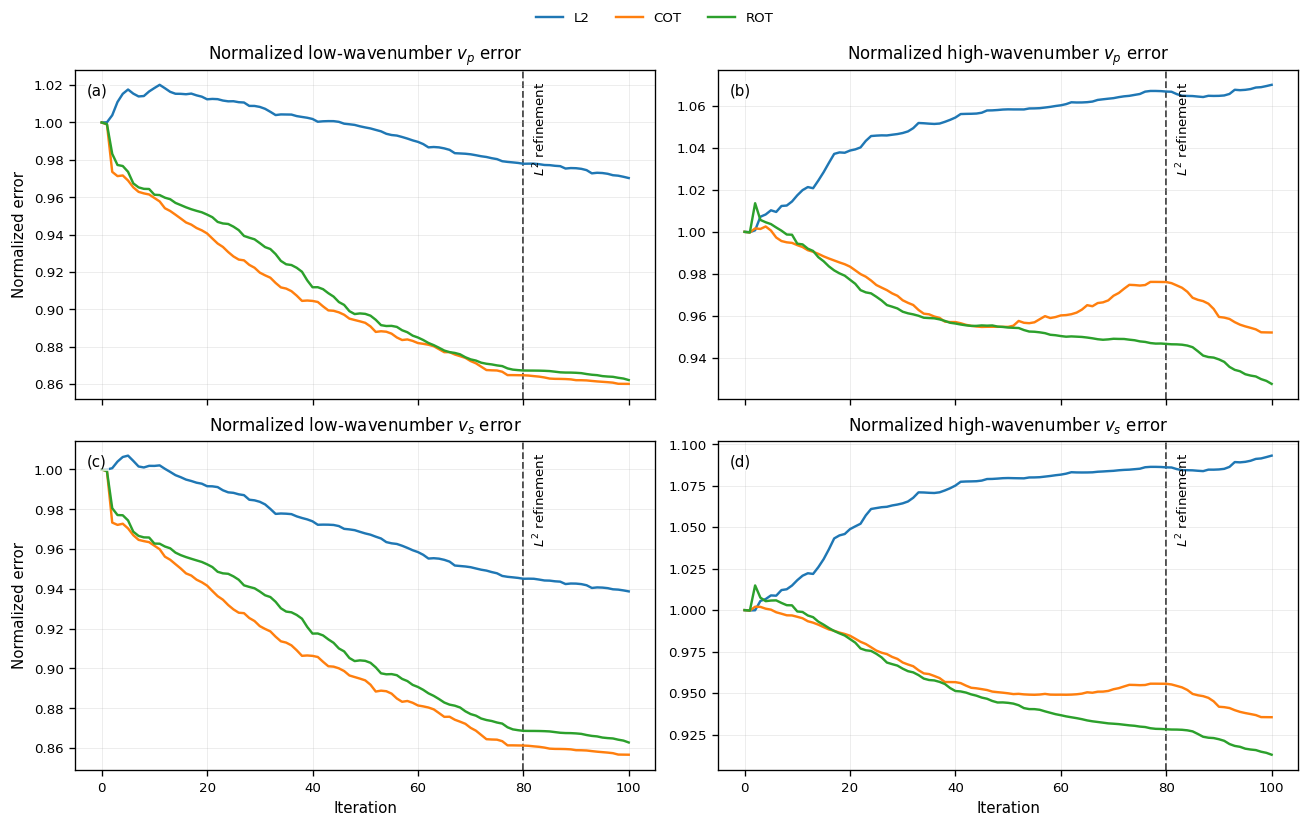

In [2]:
"""
Plot low-/high-frequency model-error histories for Marmousi inversion.

This script is intended as a supplement to the previous visualization scripts.

It produces one main figure:
    marmousi_model_error_low_high_2x2

Panels:
    (a) vp low-frequency error
    (b) vp high-frequency error
    (c) vs low-frequency error
    (d) vs high-frequency error

The error is decomposed as
    e_low  = GaussianSmooth(e)
    e_high = e - e_low
with
    e = m_k - m_true

All model arrays are cropped by data[130:-130, :] before error evaluation.
"""

from __future__ import annotations

import re
from pathlib import Path
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter


# =============================================================================
# User configuration
# =============================================================================

ROOT = Path(".")

TRUE_DIR = ROOT / "Model_1200"
RESULTS_DIR = ROOT / "Inversion_results_120_120_padding_ext_10hz"

RUN_DIRS = {
    "L2": RESULTS_DIR / "L2_smooth" / "Inv_pml_kernel_2",
    "COT": RESULTS_DIR / "COT_smooth" / "Inv_pml_kernel_2",
    "ROT": RESULTS_DIR / "ROT_corrected_smooth" / "Inv_pml_kernel_2",
}

refinement_DIRS = {
    "L2": RESULTS_DIR / "L2_smooth_con_L2" / "Inv_pml_kernel_2",
    "COT": RESULTS_DIR / "COT_smooth_con_L2" / "Inv_pml_kernel_2",
    "ROT": RESULTS_DIR / "ROT_corrected_smooth_con_L2" / "Inv_pml_kernel_2",
}

OUTPUT_DIR = ROOT / "marmousi_figures_new_corrected"

# Crop exactly as requested
CROP_LEFT = 100
CROP_RIGHT = 100

# Gaussian smoothing scale for low-frequency error decomposition.
# You can tune these two values.
SIGMA_X = 20.0
SIGMA_Z = 10.0

SAVE_FIGURES = True
SHOW_FIGURES = True
DPI = 300

METHODS = ("L2", "COT", "ROT")

plt.rcParams.update(
    {
        "font.size": 9,
        "axes.labelsize": 9,
        "axes.titlesize": 10,
        "legend.fontsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "figure.dpi": 120,
        "savefig.bbox": "tight",
    }
)


# =============================================================================
# I/O helpers
# =============================================================================

def load_array(path: Path) -> np.ndarray:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")
    arr = np.asarray(np.load(path)).squeeze()
    if arr.ndim != 2:
        raise ValueError(f"Expected a 2-D array at {path}, got {arr.shape}")
    return arr


def crop_x(data: np.ndarray) -> np.ndarray:
    if data.ndim != 2:
        raise ValueError(f"crop_x expects a 2-D array, got {data.shape}")
    nx = data.shape[0]
    if CROP_LEFT + CROP_RIGHT >= nx:
        raise ValueError(
            f"Invalid crop for nx={nx}: left={CROP_LEFT}, right={CROP_RIGHT}"
        )
    right = nx - CROP_RIGHT if CROP_RIGHT > 0 else nx
    return data[CROP_LEFT:right, :]


def _iteration_number(path: Path) -> int | None:
    for part in reversed(path.parts):
        match = re.search(r"iter[_-]?(\d+)", part, flags=re.IGNORECASE)
        if match:
            return int(match.group(1))
    return None


def discover_iteration_models(run_dir: Path, parameter: str) -> List[Tuple[int, Path]]:
    candidates = sorted(run_dir.rglob("*.npy"))
    selected: Dict[int, Path] = {}

    for path in candidates:
        name = path.name.lower()
        parent = path.parent.name.lower()

        parameter_match = (
            name == f"{parameter}.npy"
            or re.search(rf"(^|[_-]){parameter}([_.-]|$)", name) is not None
        )
        if not parameter_match:
            continue

        iteration = _iteration_number(path)
        if iteration is None:
            continue

        quality = int(name == f"{parameter}.npy") + int("iter" in parent)
        previous = selected.get(iteration)
        if previous is None:
            selected[iteration] = path
        else:
            previous_quality = (
                int(previous.name.lower() == f"{parameter}.npy")
                + int("iter" in previous.parent.name.lower())
            )
            if quality > previous_quality:
                selected[iteration] = path

    if not selected:
        raise FileNotFoundError(
            f"No iteration {parameter} models found below {run_dir}"
        )

    return sorted(selected.items(), key=lambda item: item[0])


def load_iteration_sequence(run_dir: Path, parameter: str) -> Tuple[np.ndarray, List[int]]:
    discovered = discover_iteration_models(run_dir, parameter)
    numbers = [number for number, _ in discovered]
    models = [load_array(path) for _, path in discovered]

    shape0 = models[0].shape
    for number, model in zip(numbers, models):
        if model.shape != shape0:
            raise ValueError(
                f"Inconsistent shape at iteration {number}: "
                f"{model.shape} versus {shape0}"
            )

    return np.stack(models, axis=0), numbers


# =============================================================================
# Error decomposition
# =============================================================================

def decompose_error(
    error: np.ndarray,
    sigma_x: float = SIGMA_X,
    sigma_z: float = SIGMA_Z,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Decompose a 2-D model error into low-frequency and high-frequency parts.

    e_low  = GaussianSmooth(e)
    e_high = e - e_low
    """
    e_low = gaussian_filter(error, sigma=(sigma_x, sigma_z), mode="nearest")
    e_high = error - e_low
    return e_low, e_high


def build_low_high_histories(
    first_sequence: np.ndarray,
    refinement_sequence: np.ndarray,
    truth: np.ndarray,
    sigma_x: float = SIGMA_X,
    sigma_z: float = SIGMA_Z,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Compute normalized low/high error histories.

    Each history is normalized by its own initial value:
        E_low(k)  = ||e_low(k)||  / ||e_low(0)||
        E_high(k) = ||e_high(k)|| / ||e_high(0)||
    """
    first_cropped = np.stack([crop_x(model) for model in first_sequence])
    refinement_cropped = np.stack([crop_x(model) for model in refinement_sequence])
    truth_cropped = crop_x(truth)

    low_errors = []
    high_errors = []

    def append_errors(sequence: np.ndarray, skip_first: bool = False) -> None:
        start = 1 if skip_first else 0
        for model in sequence[start:]:
            error = model - truth_cropped
            e_low, e_high = decompose_error(error, sigma_x=sigma_x, sigma_z=sigma_z)
            low_errors.append(np.linalg.norm(e_low.ravel()))
            high_errors.append(np.linalg.norm(e_high.ravel()))

    append_errors(first_cropped, skip_first=False)

    duplicate_start = False
    if refinement_cropped.shape[0] > 0:
        duplicate_start = np.allclose(
            first_cropped[-1], refinement_cropped[0], rtol=1e-6, atol=1e-7
        )
    append_errors(refinement_cropped, skip_first=duplicate_start)

    low_errors = np.asarray(low_errors, dtype=float)
    high_errors = np.asarray(high_errors, dtype=float)

    if low_errors.size == 0 or high_errors.size == 0:
        raise ValueError("Empty low/high histories computed.")

    if low_errors[0] != 0:
        low_errors = low_errors / low_errors[0]
    if high_errors[0] != 0:
        high_errors = high_errors / high_errors[0]

    return low_errors, high_errors


# =============================================================================
# Plotting
# =============================================================================

def add_panel_label(ax: plt.Axes, label: str) -> None:
    ax.text(
        0.02,
        0.96,
        label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.72, pad=1.2),
    )


def save_figure(fig: plt.Figure, stem: str) -> None:
    if not SAVE_FIGURES:
        return
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=DPI)
    fig.savefig(OUTPUT_DIR / f"{stem}.pdf")


def plot_low_high_model_errors(
    vp_low: Dict[str, np.ndarray],
    vp_high: Dict[str, np.ndarray],
    vs_low: Dict[str, np.ndarray],
    vs_high: Dict[str, np.ndarray],
    switch_iteration: int,
) -> plt.Figure:
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(10.8, 6.8),
        constrained_layout=True,
        sharex=True,
    )

    panel_map = [
        (axes[0, 0], vp_low,  r"Normalized low-wavenumber $v_p$ error"),
        (axes[0, 1], vp_high, r"Normalized high-wavenumber $v_p$ error"),
        (axes[1, 0], vs_low,  r"Normalized low-wavenumber $v_s$ error"),
        (axes[1, 1], vs_high, r"Normalized high-wavenumber $v_s$ error"),
    ]

    for idx, (ax, histories, title) in enumerate(panel_map):
        for method in METHODS:
            hist = histories[method]
            ax.plot(np.arange(hist.size), hist, linewidth=1.45, label=method)

        ax.axvline(
            switch_iteration,
            color="0.25",
            linestyle="--",
            linewidth=1.1,
            zorder=0,
        )
        ax.annotate(
            r"$L^2$ refinement",
            xy=(switch_iteration, 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(5, -7),
            textcoords="offset points",
            rotation=90,
            ha="left",
            va="top",
            fontsize=8,
        )

        ax.set_title(title)
        ax.grid(alpha=0.22, linewidth=0.6)
        add_panel_label(ax, f"({chr(97 + idx)})")

    # Axis labels only on the outer panels:
    # y labels: left column, one per row
    # x labels: bottom row, one per column
    axes[0, 0].set_ylabel("Normalized error")
    axes[1, 0].set_ylabel("Normalized error")

    axes[1, 0].set_xlabel("Iteration")
    axes[1, 1].set_xlabel("Iteration")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="outside upper center",
        ncol=3,
        frameon=False,
    )

    save_figure(fig, "marmousi_model_error_low_high_2x2_outer_labels")
    return fig


# =============================================================================
# Main
# =============================================================================

def main() -> None:
    vp_true = load_array(TRUE_DIR / "vp.npy")
    vs_true = load_array(TRUE_DIR / "vs.npy")

    vp_low_histories: Dict[str, np.ndarray] = {}
    vp_high_histories: Dict[str, np.ndarray] = {}
    vs_low_histories: Dict[str, np.ndarray] = {}
    vs_high_histories: Dict[str, np.ndarray] = {}
    switch_iterations: List[int] = []

    for method in METHODS:
        first_vp, first_vp_numbers = load_iteration_sequence(RUN_DIRS[method], "vp")
        first_vs, first_vs_numbers = load_iteration_sequence(RUN_DIRS[method], "vs")
        con_vp, con_vp_numbers = load_iteration_sequence(refinement_DIRS[method], "vp")
        con_vs, con_vs_numbers = load_iteration_sequence(refinement_DIRS[method], "vs")

        vp_low, vp_high = build_low_high_histories(first_vp, con_vp, vp_true)
        vs_low, vs_high = build_low_high_histories(first_vs, con_vs, vs_true)

        vp_low_histories[method] = vp_low
        vp_high_histories[method] = vp_high
        vs_low_histories[method] = vs_low
        vs_high_histories[method] = vs_high

        switch_iterations.append(len(first_vp) - 1)

        print(f"[{method}] vp stage-1 iterations: {first_vp_numbers[0]} ... {first_vp_numbers[-1]}")
        print(f"[{method}] vs stage-1 iterations: {first_vs_numbers[0]} ... {first_vs_numbers[-1]}")
        print(f"[{method}] vp refinement    : {con_vp_numbers[0]} ... {con_vp_numbers[-1]}")
        print(f"[{method}] vs refinement    : {con_vs_numbers[0]} ... {con_vs_numbers[-1]}")
        print(f"[{method}] history length      : {vp_low.size}")
        print()

    if len(set(switch_iterations)) != 1:
        raise ValueError(f"Inconsistent switch iterations across methods: {switch_iterations}")

    switch_iteration = switch_iterations[0]

    plot_low_high_model_errors(
        vp_low=vp_low_histories,
        vp_high=vp_high_histories,
        vs_low=vs_low_histories,
        vs_high=vs_high_histories,
        switch_iteration=switch_iteration,
    )

    if SAVE_FIGURES:
        print(f"Figures saved to: {OUTPUT_DIR.resolve()}")
    print(f"Gaussian sigma used for low-frequency decomposition: (x={SIGMA_X}, z={SIGMA_Z})")

    if SHOW_FIGURES:
        plt.show()
    else:
        plt.close("all")


if __name__ == "__main__":
    main()

[L2] vp stage-1 iterations: 0 ... 80
[L2] vs stage-1 iterations: 0 ... 80
[L2] vp refinement    : 0 ... 20
[L2] vs refinement    : 0 ... 20
[L2] shallow/deep history length: 101

[COT] vp stage-1 iterations: 0 ... 80
[COT] vs stage-1 iterations: 0 ... 80
[COT] vp refinement    : 0 ... 20
[COT] vs refinement    : 0 ... 20
[COT] shallow/deep history length: 101

[ROT] vp stage-1 iterations: 0 ... 80
[ROT] vs stage-1 iterations: 0 ... 80
[ROT] vp refinement    : 0 ... 20
[ROT] vs refinement    : 0 ... 20
[ROT] shallow/deep history length: 101

Figures saved to: C:\Users\heyuxuan\Desktop\Model_1200\marmousi_figures_new_corrected
Depth split used: shallow/middle = [0.00, 2.00) km, deep = [2.00, bottom] km


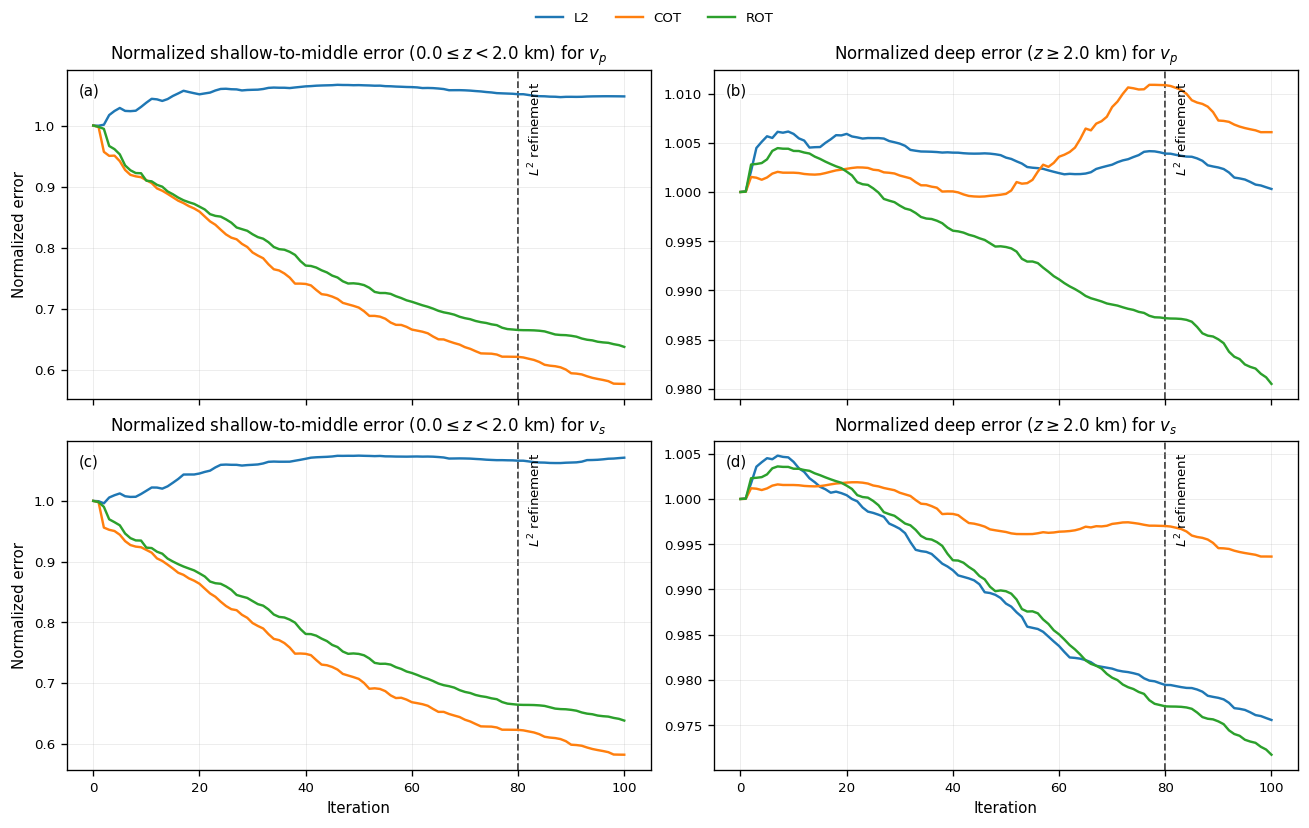

In [3]:
"""
Plot shallow/deep model-error histories for Marmousi inversion.

This script produces:
    marmousi_model_error_shallow_deep_2x2

Panels:
    (a) normalized shallow-to-middle vp error
    (b) normalized deep vp error
    (c) normalized shallow-to-middle vs error
    (d) normalized deep vs error

Definition:
    error = model_k - true_model

The model is split by depth:
    shallow/middle : TOP_DEPTH_KM <= z < SPLIT_DEPTH_KM
    deep           : SPLIT_DEPTH_KM <= z <= model bottom

All models are first cropped horizontally using:
    data = data[130:-130, :]
"""

from __future__ import annotations

import re
from pathlib import Path
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np


# =============================================================================
# User configuration
# =============================================================================

ROOT = Path(".")

TRUE_DIR = ROOT / "Model_1200"
RESULTS_DIR = ROOT / "Inversion_results_120_120_padding_ext_10hz"

RUN_DIRS = {
    "L2": RESULTS_DIR / "L2_smooth" / "Inv_pml_kernel_2",
    "COT": RESULTS_DIR / "COT_smooth" / "Inv_pml_kernel_2",
    "ROT": RESULTS_DIR / "ROT_corrected_smooth" / "Inv_pml_kernel_2",
}

refinement_DIRS = {
    "L2": RESULTS_DIR / "L2_smooth_con_L2" / "Inv_pml_kernel_2",
    "COT": RESULTS_DIR / "COT_smooth_con_L2" / "Inv_pml_kernel_2",
    "ROT": RESULTS_DIR / "ROT_corrected_smooth_con_L2" / "Inv_pml_kernel_2",
}

OUTPUT_DIR = ROOT / "marmousi_figures_new_corrected"

# Grid spacing
DZ_M = 10.0

# Horizontal crop: keep data[130:-130, :]
CROP_LEFT = 100
CROP_RIGHT = 100

# Depth split for error analysis.
# If you want to exclude the water layer, increase TOP_DEPTH_KM.
TOP_DEPTH_KM = 0.0
SPLIT_DEPTH_KM = 2.0

SAVE_FIGURES = True
SHOW_FIGURES = True
DPI = 300

METHODS = ("L2", "COT", "ROT")

plt.rcParams.update(
    {
        "font.size": 9,
        "axes.labelsize": 9,
        "axes.titlesize": 10,
        "legend.fontsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "figure.dpi": 120,
        "savefig.bbox": "tight",
    }
)


# =============================================================================
# Basic I/O helpers
# =============================================================================

def load_array(path: Path) -> np.ndarray:
    """Load a 2-D NumPy array."""
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")
    arr = np.asarray(np.load(path)).squeeze()
    if arr.ndim != 2:
        raise ValueError(f"Expected a 2-D array at {path}, got shape {arr.shape}")
    return arr


def crop_x(data: np.ndarray) -> np.ndarray:
    """Apply the required horizontal crop: data[130:-130, :]."""
    if data.ndim != 2:
        raise ValueError(f"crop_x expects a 2-D array, got shape {data.shape}")
    nx = data.shape[0]
    if CROP_LEFT + CROP_RIGHT >= nx:
        raise ValueError(
            f"Invalid crop: left={CROP_LEFT}, right={CROP_RIGHT}, nx={nx}"
        )
    right = nx - CROP_RIGHT if CROP_RIGHT > 0 else nx
    return data[CROP_LEFT:right, :]


def _iteration_number(path: Path) -> int | None:
    for part in reversed(path.parts):
        match = re.search(r"iter[_-]?(\d+)", part, flags=re.IGNORECASE)
        if match:
            return int(match.group(1))
    return None


def discover_iteration_models(run_dir: Path, parameter: str) -> List[Tuple[int, Path]]:
    candidates = sorted(run_dir.rglob("*.npy"))
    selected: Dict[int, Path] = {}

    for path in candidates:
        name = path.name.lower()
        parent = path.parent.name.lower()

        parameter_match = (
            name == f"{parameter}.npy"
            or re.search(rf"(^|[_-]){parameter}([_.-]|$)", name) is not None
        )
        if not parameter_match:
            continue

        iteration = _iteration_number(path)
        if iteration is None:
            continue

        quality = int(name == f"{parameter}.npy") + int("iter" in parent)
        previous = selected.get(iteration)

        if previous is None:
            selected[iteration] = path
        else:
            previous_quality = (
                int(previous.name.lower() == f"{parameter}.npy")
                + int("iter" in previous.parent.name.lower())
            )
            if quality > previous_quality:
                selected[iteration] = path

    if not selected:
        raise FileNotFoundError(
            f"No iteration {parameter} models were found below {run_dir}"
        )

    return sorted(selected.items(), key=lambda item: item[0])


def load_iteration_sequence(run_dir: Path, parameter: str) -> Tuple[np.ndarray, List[int]]:
    discovered = discover_iteration_models(run_dir, parameter)
    numbers = [number for number, _ in discovered]
    models = [load_array(path) for _, path in discovered]

    shape0 = models[0].shape
    for number, model in zip(numbers, models):
        if model.shape != shape0:
            raise ValueError(
                f"Inconsistent shape at iteration {number}: "
                f"{model.shape} versus {shape0}"
            )

    return np.stack(models, axis=0), numbers


# =============================================================================
# Shallow/deep error computation
# =============================================================================

def depth_to_index(depth_km: float, dz_m: float, nz: int) -> int:
    index = int(round(depth_km * 1000.0 / dz_m))
    return int(np.clip(index, 0, nz))


def build_shallow_deep_histories(
    first_sequence: np.ndarray,
    refinement_sequence: np.ndarray,
    truth: np.ndarray,
    split_depth_km: float = SPLIT_DEPTH_KM,
    dz_m: float = DZ_M,
    top_depth_km: float = TOP_DEPTH_KM,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Compute normalized shallow/deep model-error histories.
    """
    first_cropped = np.stack([crop_x(model) for model in first_sequence])
    refinement_cropped = np.stack([crop_x(model) for model in refinement_sequence])
    truth_cropped = crop_x(truth)

    nz = truth_cropped.shape[1]

    top_index = depth_to_index(top_depth_km, dz_m, nz)
    split_index = depth_to_index(split_depth_km, dz_m, nz)

    if split_index <= top_index:
        raise ValueError(
            "split_depth_km must be strictly larger than top_depth_km."
        )
    if split_index >= nz:
        raise ValueError(
            f"split_depth_km={split_depth_km} km lies below the model bottom."
        )

    shallow_errors: List[float] = []
    deep_errors: List[float] = []

    def append_errors(sequence: np.ndarray, skip_first: bool = False) -> None:
        start = 1 if skip_first else 0
        for model in sequence[start:]:
            error = model - truth_cropped

            shallow_error = error[:, top_index:split_index]
            deep_error = error[:, split_index:]

            shallow_errors.append(np.linalg.norm(shallow_error.ravel()))
            deep_errors.append(np.linalg.norm(deep_error.ravel()))

    append_errors(first_cropped, skip_first=False)

    duplicate_start = False
    if refinement_cropped.shape[0] > 0:
        duplicate_start = np.allclose(
            first_cropped[-1],
            refinement_cropped[0],
            rtol=1e-6,
            atol=1e-7,
        )
    append_errors(refinement_cropped, skip_first=duplicate_start)

    shallow_errors = np.asarray(shallow_errors, dtype=float)
    deep_errors = np.asarray(deep_errors, dtype=float)

    if shallow_errors.size == 0 or deep_errors.size == 0:
        raise ValueError("Empty shallow/deep histories computed.")

    if shallow_errors[0] != 0:
        shallow_errors = shallow_errors / shallow_errors[0]
    if deep_errors[0] != 0:
        deep_errors = deep_errors / deep_errors[0]

    return shallow_errors, deep_errors


# =============================================================================
# Plotting helpers
# =============================================================================

def add_panel_label(ax: plt.Axes, label: str) -> None:
    ax.text(
        0.02,
        0.96,
        label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.72, pad=1.2),
    )


def save_figure(fig: plt.Figure, stem: str) -> None:
    if not SAVE_FIGURES:
        return
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=DPI)
    fig.savefig(OUTPUT_DIR / f"{stem}.pdf")


def plot_shallow_deep_model_errors(
    vp_shallow: Dict[str, np.ndarray],
    vp_deep: Dict[str, np.ndarray],
    vs_shallow: Dict[str, np.ndarray],
    vs_deep: Dict[str, np.ndarray],
    switch_iteration: int,
    split_depth_km: float,
    top_depth_km: float,
) -> plt.Figure:
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(10.8, 6.8),
        constrained_layout=True,
        sharex=True,
    )

    shallow_title = (
        rf"Normalized shallow-to-middle error "
        rf"(${top_depth_km:.1f} \leq z < {split_depth_km:.1f}$ km)"
    )
    deep_title = (
        rf"Normalized deep error "
        rf"($z \geq {split_depth_km:.1f}$ km)"
    )

    panels = [
        (axes[0, 0], vp_shallow, shallow_title + r" for $v_p$"),
        (axes[0, 1], vp_deep,    deep_title    + r" for $v_p$"),
        (axes[1, 0], vs_shallow, shallow_title + r" for $v_s$"),
        (axes[1, 1], vs_deep,    deep_title    + r" for $v_s$"),
    ]

    for panel_index, (ax, histories, title) in enumerate(panels):
        for method in METHODS:
            history = histories[method]
            ax.plot(
                np.arange(history.size),
                history,
                linewidth=1.45,
                label=method,
            )

        ax.axvline(
            switch_iteration,
            color="0.25",
            linestyle="--",
            linewidth=1.1,
            zorder=0,
        )

        ax.annotate(
            r"$L^2$ refinement",
            xy=(switch_iteration, 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(5, -7),
            textcoords="offset points",
            rotation=90,
            ha="left",
            va="top",
            fontsize=8,
        )

        ax.set_title(title)
        ax.grid(alpha=0.22, linewidth=0.6)
        add_panel_label(ax, f"({chr(97 + panel_index)})")

    # Axis labels only on the outer panels:
    # y labels: left column, one per row
    # x labels: bottom row, one per column
    axes[0, 0].set_ylabel("Normalized error")
    axes[1, 0].set_ylabel("Normalized error")

    axes[1, 0].set_xlabel("Iteration")
    axes[1, 1].set_xlabel("Iteration")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="outside upper center",
        ncol=3,
        frameon=False,
    )

    save_figure(fig, "marmousi_model_error_shallow_deep_2x2_outer_labels")
    return fig


# =============================================================================
# Main
# =============================================================================

def main() -> None:
    vp_true = load_array(TRUE_DIR / "vp.npy")
    vs_true = load_array(TRUE_DIR / "vs.npy")

    if vp_true.shape != vs_true.shape:
        raise ValueError(
            f"vp_true shape {vp_true.shape} != vs_true shape {vs_true.shape}"
        )

    vp_shallow_histories: Dict[str, np.ndarray] = {}
    vp_deep_histories: Dict[str, np.ndarray] = {}
    vs_shallow_histories: Dict[str, np.ndarray] = {}
    vs_deep_histories: Dict[str, np.ndarray] = {}

    switch_iterations: List[int] = []

    for method in METHODS:
        first_vp, first_vp_numbers = load_iteration_sequence(RUN_DIRS[method], "vp")
        first_vs, first_vs_numbers = load_iteration_sequence(RUN_DIRS[method], "vs")

        con_vp, con_vp_numbers = load_iteration_sequence(
            refinement_DIRS[method], "vp"
        )
        con_vs, con_vs_numbers = load_iteration_sequence(
            refinement_DIRS[method], "vs"
        )

        vp_shallow, vp_deep = build_shallow_deep_histories(
            first_sequence=first_vp,
            refinement_sequence=con_vp,
            truth=vp_true,
            split_depth_km=SPLIT_DEPTH_KM,
            dz_m=DZ_M,
            top_depth_km=TOP_DEPTH_KM,
        )

        vs_shallow, vs_deep = build_shallow_deep_histories(
            first_sequence=first_vs,
            refinement_sequence=con_vs,
            truth=vs_true,
            split_depth_km=SPLIT_DEPTH_KM,
            dz_m=DZ_M,
            top_depth_km=TOP_DEPTH_KM,
        )

        vp_shallow_histories[method] = vp_shallow
        vp_deep_histories[method] = vp_deep
        vs_shallow_histories[method] = vs_shallow
        vs_deep_histories[method] = vs_deep

        switch_iterations.append(len(first_vp) - 1)

        print(f"[{method}] vp stage-1 iterations: {first_vp_numbers[0]} ... {first_vp_numbers[-1]}")
        print(f"[{method}] vs stage-1 iterations: {first_vs_numbers[0]} ... {first_vs_numbers[-1]}")
        print(f"[{method}] vp refinement    : {con_vp_numbers[0]} ... {con_vp_numbers[-1]}")
        print(f"[{method}] vs refinement    : {con_vs_numbers[0]} ... {con_vs_numbers[-1]}")
        print(f"[{method}] shallow/deep history length: {vp_shallow.size}")
        print()

    if len(set(switch_iterations)) != 1:
        raise ValueError(
            f"Inconsistent switch iterations across methods: {switch_iterations}"
        )

    switch_iteration = switch_iterations[0]

    plot_shallow_deep_model_errors(
        vp_shallow=vp_shallow_histories,
        vp_deep=vp_deep_histories,
        vs_shallow=vs_shallow_histories,
        vs_deep=vs_deep_histories,
        switch_iteration=switch_iteration,
        split_depth_km=SPLIT_DEPTH_KM,
        top_depth_km=TOP_DEPTH_KM,
    )

    if SAVE_FIGURES:
        print(f"Figures saved to: {OUTPUT_DIR.resolve()}")

    print(
        f"Depth split used: shallow/middle = [{TOP_DEPTH_KM:.2f}, "
        f"{SPLIT_DEPTH_KM:.2f}) km, deep = [{SPLIT_DEPTH_KM:.2f}, bottom] km"
    )

    if SHOW_FIGURES:
        plt.show()
    else:
        plt.close("all")


if __name__ == "__main__":
    main()


Ablation inputs:
  lambda=0 stage        : Inversion_results_120_120_padding_ext_10hz\ROT0_smooth\Inv_pml_kernel_2
  lambda=5e-3 stage     : Inversion_results_120_120_padding_ext_10hz\ROT_corrected_smooth\Inv_pml_kernel_2
  lambda=0 refined      : Inversion_results_120_120_padding_ext_10hz\ROT0_smooth_con_L2\Inv_pml_kernel_2
  lambda=5e-3 refined   : Inversion_results_120_120_padding_ext_10hz\ROT_corrected_smooth_con_L2\Inv_pml_kernel_2

Iteration ranges:
  ROT lambda=0          : 0 ... 80
  ROT lambda=5e-3       : 0 ... 80
  lambda=0 refinement   : 0 ... 20
  lambda=5e-3 refinement: 0 ... 20

Normalized model errors:
  vp, lambda=0 stage          : 0.934514
  vp, lambda=5e-3 stage       : 0.898715
  vp, lambda=0 refined        : 0.913064
  vp, lambda=5e-3 refined     : 0.887347
  vs, lambda=0 stage          : 0.931409
  vs, lambda=5e-3 stage       : 0.890965
  vs, lambda=0 refined        : 0.912184
  vs, lambda=5e-3 refined     : 0.880917

Figures saved to: C:\Users\heyuxuan\Desktop\

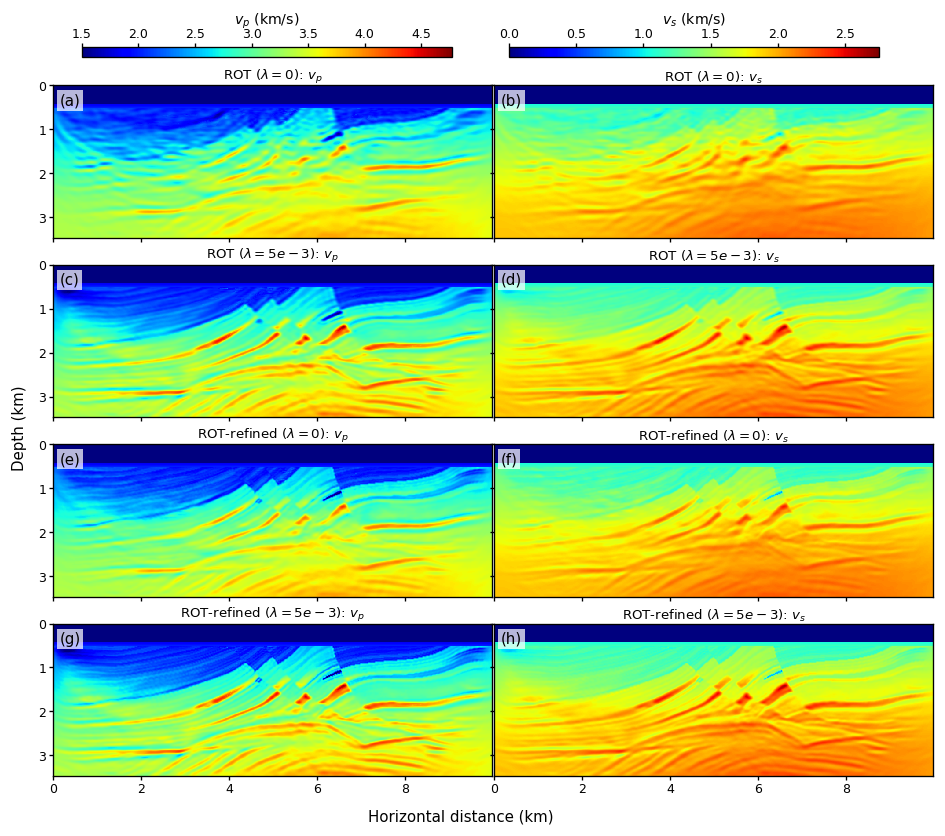

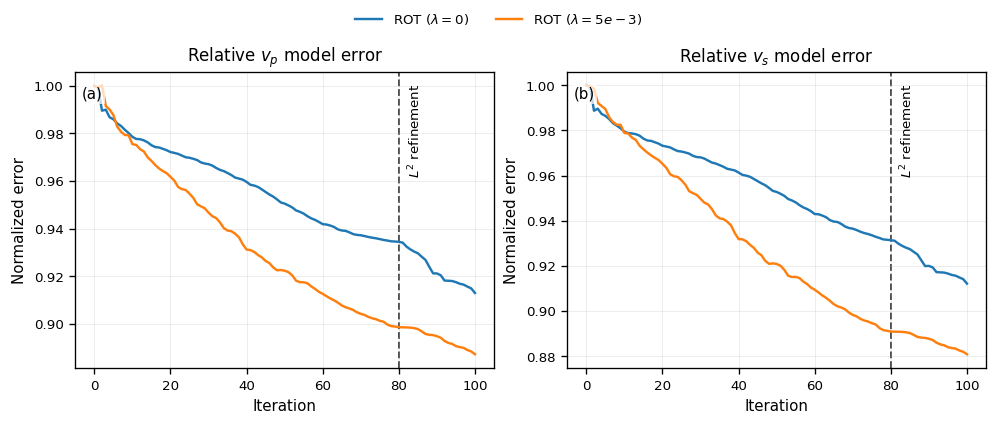

In [ ]:
from __future__ import annotations

import re
from pathlib import Path
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np


# =============================================================================
# User configuration
# =============================================================================

ROOT = Path(".")

TRUE_DIR = ROOT / "Model_1200"
INITIAL_DIR = ROOT / "Initial_models" / "Initial_120_120_padding_1200"
RESULTS_DIR = ROOT / "Inversion_results_120_120_padding_ext_10hz"

# ROT ablation runs
ROT0_DIR = RESULTS_DIR / "ROT0_smooth" / "Inv_pml_kernel_2"
ROT_DIR = RESULTS_DIR / "ROT_corrected_smooth" / "Inv_pml_kernel_2"
ROT0_REFINED_DIR = RESULTS_DIR / "ROT0_smooth_con_L2" / "Inv_pml_kernel_2"
ROT_REFINED_DIR = RESULTS_DIR / "ROT_corrected_smooth_con_L2" / "Inv_pml_kernel_2"

OUTPUT_DIR = ROOT / "rot_lambda_ablation_figures_corrected"

DX_M = 10.0
DZ_M = 10.0

# Same horizontal cropping used in the previous Marmousi figures.
CROP_LEFT = 100
CROP_RIGHT = 100

KEEP_ORIGINAL_X_COORD = False

SAVE_FIGURES = True
SHOW_FIGURES = True
DPI = 300

VP_CLIM = None
VS_CLIM = None

# lambda values used in the comparison
LAMBDA_FULL = 5e-3

plt.rcParams.update(
    {
        "font.size": 9,
        "axes.labelsize": 9,
        "axes.titlesize": 10,
        "legend.fontsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "figure.dpi": 120,
        "savefig.bbox": "tight",
    }
)


# =============================================================================
# Loading helpers
# =============================================================================

def load_array(path: Path) -> np.ndarray:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

    arr = np.asarray(np.load(path)).squeeze()
    if arr.ndim != 2:
        raise ValueError(f"Expected a 2-D model at {path}, got shape {arr.shape}")
    return arr


def crop_x(data: np.ndarray) -> np.ndarray:
    nx = data.shape[0]
    if CROP_LEFT + CROP_RIGHT >= nx:
        raise ValueError(
            f"Invalid crop: left={CROP_LEFT}, right={CROP_RIGHT}, nx={nx}"
        )

    right = nx - CROP_RIGHT if CROP_RIGHT > 0 else nx
    return data[CROP_LEFT:right, :]


def load_final_model(run_dir: Path, parameter: str) -> np.ndarray:
    direct = run_dir / "final" / f"{parameter}.npy"
    if direct.exists():
        return load_array(direct)

    matches = sorted(run_dir.rglob(f"{parameter}.npy"))
    final_matches = [p for p in matches if p.parent.name.lower() == "final"]

    if len(final_matches) == 1:
        return load_array(final_matches[0])

    if len(final_matches) > 1:
        raise RuntimeError(
            f"Ambiguous final {parameter} files in {run_dir}:\n"
            + "\n".join(map(str, final_matches))
        )

    raise FileNotFoundError(
        f"Could not find final/{parameter}.npy below {run_dir}"
    )


def _iteration_number(path: Path) -> int | None:
    for part in reversed(path.parts):
        match = re.search(r"iter[_-]?(\d+)", part, flags=re.IGNORECASE)
        if match:
            return int(match.group(1))
    return None


def discover_iteration_models(
    run_dir: Path,
    parameter: str,
) -> List[Tuple[int, Path]]:
    candidates = sorted(run_dir.rglob("*.npy"))
    selected: Dict[int, Path] = {}

    for path in candidates:
        name = path.name.lower()
        parent = path.parent.name.lower()

        parameter_match = (
            name == f"{parameter}.npy"
            or re.search(rf"(^|[_-]){parameter}([_.-]|$)", name) is not None
        )
        if not parameter_match:
            continue

        iteration = _iteration_number(path)
        if iteration is None:
            continue

        quality = int(name == f"{parameter}.npy") + int("iter" in parent)

        previous = selected.get(iteration)
        if previous is None:
            selected[iteration] = path
        else:
            previous_quality = (
                int(previous.name.lower() == f"{parameter}.npy")
                + int("iter" in previous.parent.name.lower())
            )
            if quality > previous_quality:
                selected[iteration] = path

    if not selected:
        raise FileNotFoundError(
            f"No iteration {parameter} models found below {run_dir}"
        )

    return sorted(selected.items(), key=lambda item: item[0])


def load_iteration_sequence(
    run_dir: Path,
    parameter: str,
) -> Tuple[np.ndarray, List[int]]:
    discovered = discover_iteration_models(run_dir, parameter)

    numbers = [number for number, _ in discovered]
    models = [load_array(path) for _, path in discovered]

    shape0 = models[0].shape
    for number, model in zip(numbers, models):
        if model.shape != shape0:
            raise ValueError(
                f"Inconsistent model shape at iteration {number}: "
                f"{model.shape} versus {shape0}"
            )

    return np.stack(models, axis=0), numbers


# =============================================================================
# Geometry / error helpers
# =============================================================================

def model_extent_km(model_cropped: np.ndarray) -> Tuple[float, float, float, float]:
    nx, nz = model_cropped.shape

    x0 = (
        CROP_LEFT * DX_M / 1000.0
        if KEEP_ORIGINAL_X_COORD
        else 0.0
    )

    x1 = x0 + (nx - 1) * DX_M / 1000.0
    z1 = (nz - 1) * DZ_M / 1000.0

    return x0, x1, z1, 0.0


def infer_clim(truth_cropped: np.ndarray, configured):
    if configured is not None:
        return tuple(configured)

    return (
        float(np.nanmin(truth_cropped)),
        float(np.nanmax(truth_cropped)),
    )


def relative_error(model: np.ndarray, truth: np.ndarray) -> float:
    """
    Same normalized model-error convention used in the Marmousi analysis:

        ||m_i - m_true||_2 / ||m_0 - m_true||_2

    This helper returns only the numerator. Normalization by the initial
    error is performed after constructing the complete history.
    """
    return float(np.linalg.norm((model - truth).ravel()))


def normalized_error_history(
    sequence: np.ndarray,
    truth: np.ndarray,
    initial: np.ndarray,
) -> np.ndarray:
    truth_c = crop_x(truth)
    initial_c = crop_x(initial)

    initial_error = relative_error(initial_c, truth_c)
    if initial_error == 0:
        raise ZeroDivisionError("Initial model error is zero.")

    values = np.array(
        [
            relative_error(crop_x(model), truth_c) / initial_error
            for model in sequence
        ],
        dtype=float,
    )
    return values


def concatenate_stage_and_refinement(
    stage_sequence: np.ndarray,
    refinement_sequence: np.ndarray,
) -> np.ndarray:
    """
    Concatenate ROT stage-1 and L2-refinement model sequences.

    If refinement_sequence[0] duplicates stage_sequence[-1], the duplicated
    starting model is removed.
    """
    if len(refinement_sequence) == 0:
        return stage_sequence.copy()

    if np.allclose(
        stage_sequence[-1],
        refinement_sequence[0],
        rtol=1e-6,
        atol=1e-7,
    ):
        refinement_sequence = refinement_sequence[1:]

    return np.concatenate(
        [stage_sequence, refinement_sequence],
        axis=0,
    )


def add_panel_label(ax: plt.Axes, label: str) -> None:
    ax.text(
        0.015,
        0.95,
        label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        color="black",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.72,
            pad=1.5,
        ),
    )


def save_figure(fig: plt.Figure, stem: str) -> None:
    if not SAVE_FIGURES:
        return

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=DPI)
    fig.savefig(OUTPUT_DIR / f"{stem}.pdf")


# =============================================================================
# Figure 1:
# ROT lambda ablation + L2 refinement in ONE 4 x 2 figure
# =============================================================================

def plot_ablation_models(
    vp_true: np.ndarray,
    vs_true: np.ndarray,
    vp_rot0: np.ndarray,
    vs_rot0: np.ndarray,
    vp_rot: np.ndarray,
    vs_rot: np.ndarray,
    vp_rot0_refined: np.ndarray,
    vs_rot0_refined: np.ndarray,
    vp_rot_refined: np.ndarray,
    vs_rot_refined: np.ndarray,
) -> plt.Figure:
    """
    Rows:
      1. ROT lambda=0 after the 80-step smoothed-gradient stage
      2. ROT lambda=5e-3 after the same 80-step stage
      3. ROT lambda=0 after the subsequent L2 refinement
      4. ROT lambda=5e-3 after the subsequent L2 refinement

    This gives a controlled comparison both before and after refinement.
    """

    panels = [
        [crop_x(vp_rot0), crop_x(vs_rot0)],
        [crop_x(vp_rot), crop_x(vs_rot)],
        [crop_x(vp_rot0_refined), crop_x(vs_rot0_refined)],
        [crop_x(vp_rot_refined), crop_x(vs_rot_refined)],
    ]

    row_names = [
        r"ROT ($\lambda=0$)",
        rf"ROT ($\lambda=5e-3$)",
        r"ROT-refined ($\lambda=0$)",
        rf"ROT-refined ($\lambda=5e-3$)",
    ]

    parameter_names = [r"$v_p$", r"$v_s$"]

    vp_truth = crop_x(vp_true)
    vs_truth = crop_x(vs_true)

    clims = [
        infer_clim(vp_truth, VP_CLIM),
        infer_clim(vs_truth, VS_CLIM),
    ]

    extent = model_extent_km(vp_truth)

    panel_labels = [
        ["(a)", "(b)"],
        ["(c)", "(d)"],
        ["(e)", "(f)"],
        ["(g)", "(h)"],
    ]

    fig = plt.figure(figsize=(8.0, 7.05))

    gs = fig.add_gridspec(
        4,
        2,
        width_ratios=[1, 1],
        height_ratios=[1, 1, 1, 1],
        wspace=0.005,
        hspace=0.105,
    )

    ims = [None, None]

    for i in range(4):
        for j in range(2):
            ax = fig.add_subplot(gs[i, j])

            im = ax.imshow(
                panels[i][j].T,
                cmap="jet",
                origin="upper",
                extent=extent,
                aspect="equal",
                vmin=clims[j][0],
                vmax=clims[j][1],
                interpolation="nearest",
            )

            ims[j] = im
            add_panel_label(ax, panel_labels[i][j])

            ax.set_title(
                rf"{row_names[i]}: {parameter_names[j]}",
                fontsize=8.0,
                pad=0.8,
            )

            ax.tick_params(
                axis="both",
                which="major",
                labelsize=7.5,
                length=2.5,
                pad=1.5,
            )

            if i != 3:
                ax.tick_params(labelbottom=False)

            if j != 0:
                ax.tick_params(labelleft=False)

    fig.subplots_adjust(
        left=0.075,
        right=0.992,
        bottom=0.072,
        top=0.900,
    )

    cax_vp = fig.add_axes([0.105, 0.928, 0.385, 0.012])
    cax_vs = fig.add_axes([0.550, 0.928, 0.385, 0.012])

    cbar_vp = fig.colorbar(
        ims[0],
        cax=cax_vp,
        orientation="horizontal",
    )
    cbar_vp.set_label(r"$v_p$ (km/s)", fontsize=8.5, labelpad=2)
    cbar_vp.ax.tick_params(labelsize=7.5, length=2.5, pad=1.0)
    cbar_vp.ax.xaxis.set_ticks_position("top")
    cbar_vp.ax.xaxis.set_label_position("top")

    cbar_vs = fig.colorbar(
        ims[1],
        cax=cax_vs,
        orientation="horizontal",
    )
    cbar_vs.set_label(r"$v_s$ (km/s)", fontsize=8.5, labelpad=2)
    cbar_vs.ax.tick_params(labelsize=7.5, length=2.5, pad=1.0)
    cbar_vs.ax.xaxis.set_ticks_position("top")
    cbar_vs.ax.xaxis.set_label_position("top")

    fig.text(
        0.50,
        0.030,
        "Horizontal distance (km)",
        ha="center",
        va="center",
        fontsize=9,
    )

    fig.text(
        0.040,
        0.49,
        "Depth (km)",
        ha="center",
        va="center",
        rotation="vertical",
        fontsize=9,
    )

    save_figure(
        fig,
        "ROT_lambda_ablation_and_refinement_models_4x2",
    )

    return fig


# =============================================================================
# Figure 2:
# Overall vp/vs model-error histories, including refinement for BOTH lambdas
# =============================================================================

def plot_ablation_error_histories(
    vp_error_rot0_full: np.ndarray,
    vs_error_rot0_full: np.ndarray,
    vp_error_rot_full: np.ndarray,
    vs_error_rot_full: np.ndarray,
    switch_iteration: int,
) -> plt.Figure:

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(8.2, 3.45),
        constrained_layout=True,
    )

    x0_vp = np.arange(vp_error_rot0_full.size)
    x0_vs = np.arange(vs_error_rot0_full.size)
    xfull_vp = np.arange(vp_error_rot_full.size)
    xfull_vs = np.arange(vs_error_rot_full.size)

    label_rot0 = r"ROT ($\lambda=0$)"
    label_rot = rf"ROT ($\lambda=5e-3$)"

    axes[0].plot(
        x0_vp,
        vp_error_rot0_full,
        linewidth=1.45,
        label=label_rot0,
    )
    axes[0].plot(
        xfull_vp,
        vp_error_rot_full,
        linewidth=1.45,
        label=label_rot,
    )

    axes[1].plot(
        x0_vs,
        vs_error_rot0_full,
        linewidth=1.45,
        label=label_rot0,
    )
    axes[1].plot(
        xfull_vs,
        vs_error_rot_full,
        linewidth=1.45,
        label=label_rot,
    )

    for i, ax in enumerate(axes):
        ax.axvline(
            switch_iteration,
            color="0.25",
            linestyle="--",
            linewidth=1.1,
            zorder=0,
        )

        ax.annotate(
            r"$L^2$ refinement",
            xy=(switch_iteration, 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(5, -7),
            textcoords="offset points",
            rotation=90,
            ha="left",
            va="top",
            fontsize=8,
        )

        ax.grid(alpha=0.22, linewidth=0.6)
        ax.set_xlabel("Iteration")
        ax.set_ylabel("Normalized error")
        add_panel_label(ax, f"({chr(97 + i)})")

    axes[0].set_title(r"Relative $v_p$ model error")
    axes[1].set_title(r"Relative $v_s$ model error")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="outside upper center",
        ncol=2,
        frameon=False,
    )

    save_figure(
        fig,
        "ROT_lambda_ablation_model_errors_1x2",
    )

    return fig


# =============================================================================
# Main
# =============================================================================

def main() -> None:
    # -------------------------------------------------------------------------
    # True / initial
    # -------------------------------------------------------------------------
    vp_true = load_array(TRUE_DIR / "vp.npy")
    vs_true = load_array(TRUE_DIR / "vs.npy")

    vp_initial = load_array(INITIAL_DIR / "vp.npy")
    vs_initial = load_array(INITIAL_DIR / "vs.npy")

    # -------------------------------------------------------------------------
    # Final models: both lambda values, before and after L2 refinement
    # -------------------------------------------------------------------------
    vp_rot0 = load_final_model(ROT0_DIR, "vp")
    vs_rot0 = load_final_model(ROT0_DIR, "vs")

    vp_rot = load_final_model(ROT_DIR, "vp")
    vs_rot = load_final_model(ROT_DIR, "vs")

    vp_rot0_refined = load_final_model(
        ROT0_REFINED_DIR,
        "vp",
    )
    vs_rot0_refined = load_final_model(
        ROT0_REFINED_DIR,
        "vs",
    )

    vp_rot_refined = load_final_model(
        ROT_REFINED_DIR,
        "vp",
    )
    vs_rot_refined = load_final_model(
        ROT_REFINED_DIR,
        "vs",
    )

    # -------------------------------------------------------------------------
    # Figure 1: one combined 4 x 2 model figure
    # -------------------------------------------------------------------------
    plot_ablation_models(
        vp_true=vp_true,
        vs_true=vs_true,
        vp_rot0=vp_rot0,
        vs_rot0=vs_rot0,
        vp_rot=vp_rot,
        vs_rot=vs_rot,
        vp_rot0_refined=vp_rot0_refined,
        vs_rot0_refined=vs_rot0_refined,
        vp_rot_refined=vp_rot_refined,
        vs_rot_refined=vs_rot_refined,
    )

    # -------------------------------------------------------------------------
    # Iteration sequences
    # -------------------------------------------------------------------------
    rot0_vp_seq, rot0_vp_numbers = load_iteration_sequence(
        ROT0_DIR,
        "vp",
    )
    rot0_vs_seq, rot0_vs_numbers = load_iteration_sequence(
        ROT0_DIR,
        "vs",
    )

    rot_vp_seq, rot_vp_numbers = load_iteration_sequence(
        ROT_DIR,
        "vp",
    )
    rot_vs_seq, rot_vs_numbers = load_iteration_sequence(
        ROT_DIR,
        "vs",
    )

    rot0_refined_vp_seq, rot0_refined_vp_numbers = load_iteration_sequence(
        ROT0_REFINED_DIR,
        "vp",
    )
    rot0_refined_vs_seq, rot0_refined_vs_numbers = load_iteration_sequence(
        ROT0_REFINED_DIR,
        "vs",
    )

    refined_vp_seq, refined_vp_numbers = load_iteration_sequence(
        ROT_REFINED_DIR,
        "vp",
    )
    refined_vs_seq, refined_vs_numbers = load_iteration_sequence(
        ROT_REFINED_DIR,
        "vs",
    )

    # Full histories = ROT stage + L2 refinement.
    rot0_full_vp_seq = concatenate_stage_and_refinement(
        rot0_vp_seq,
        rot0_refined_vp_seq,
    )
    rot0_full_vs_seq = concatenate_stage_and_refinement(
        rot0_vs_seq,
        rot0_refined_vs_seq,
    )

    rot_full_vp_seq = concatenate_stage_and_refinement(
        rot_vp_seq,
        refined_vp_seq,
    )
    rot_full_vs_seq = concatenate_stage_and_refinement(
        rot_vs_seq,
        refined_vs_seq,
    )

    vp_error_rot0_full = normalized_error_history(
        rot0_full_vp_seq,
        truth=vp_true,
        initial=vp_initial,
    )
    vs_error_rot0_full = normalized_error_history(
        rot0_full_vs_seq,
        truth=vs_true,
        initial=vs_initial,
    )

    vp_error_rot_full = normalized_error_history(
        rot_full_vp_seq,
        truth=vp_true,
        initial=vp_initial,
    )
    vs_error_rot_full = normalized_error_history(
        rot_full_vs_seq,
        truth=vs_true,
        initial=vs_initial,
    )

    # Stage-only errors, useful for terminal reporting.
    vp_error_rot0_stage = normalized_error_history(
        rot0_vp_seq,
        truth=vp_true,
        initial=vp_initial,
    )
    vs_error_rot0_stage = normalized_error_history(
        rot0_vs_seq,
        truth=vs_true,
        initial=vs_initial,
    )
    vp_error_rot_stage = normalized_error_history(
        rot_vp_seq,
        truth=vp_true,
        initial=vp_initial,
    )
    vs_error_rot_stage = normalized_error_history(
        rot_vs_seq,
        truth=vs_true,
        initial=vs_initial,
    )

    switch_iteration = len(rot_vp_seq) - 1

    # -------------------------------------------------------------------------
    # Figure 2: full error histories for both lambda values
    # -------------------------------------------------------------------------
    plot_ablation_error_histories(
        vp_error_rot0_full=vp_error_rot0_full,
        vs_error_rot0_full=vs_error_rot0_full,
        vp_error_rot_full=vp_error_rot_full,
        vs_error_rot_full=vs_error_rot_full,
        switch_iteration=switch_iteration,
    )

    print("\nAblation inputs:")
    print(f"  lambda=0 stage        : {ROT0_DIR}")
    print(f"  lambda=5e-3 stage     : {ROT_DIR}")
    print(f"  lambda=0 refined      : {ROT0_REFINED_DIR}")
    print(f"  lambda=5e-3 refined   : {ROT_REFINED_DIR}")

    print("\nIteration ranges:")
    print(
        f"  ROT lambda=0          : "
        f"{rot0_vp_numbers[0]} ... {rot0_vp_numbers[-1]}"
    )
    print(
        f"  ROT lambda=5e-3       : "
        f"{rot_vp_numbers[0]} ... {rot_vp_numbers[-1]}"
    )
    print(
        f"  lambda=0 refinement   : "
        f"{rot0_refined_vp_numbers[0]} ... {rot0_refined_vp_numbers[-1]}"
    )
    print(
        f"  lambda=5e-3 refinement: "
        f"{refined_vp_numbers[0]} ... {refined_vp_numbers[-1]}"
    )

    print("\nNormalized model errors:")
    print(f"  vp, lambda=0 stage          : {vp_error_rot0_stage[-1]:.6f}")
    print(f"  vp, lambda=5e-3 stage       : {vp_error_rot_stage[-1]:.6f}")
    print(f"  vp, lambda=0 refined        : {vp_error_rot0_full[-1]:.6f}")
    print(f"  vp, lambda=5e-3 refined     : {vp_error_rot_full[-1]:.6f}")
    print(f"  vs, lambda=0 stage          : {vs_error_rot0_stage[-1]:.6f}")
    print(f"  vs, lambda=5e-3 stage       : {vs_error_rot_stage[-1]:.6f}")
    print(f"  vs, lambda=0 refined        : {vs_error_rot0_full[-1]:.6f}")
    print(f"  vs, lambda=5e-3 refined     : {vs_error_rot_full[-1]:.6f}")

    if SAVE_FIGURES:
        print(f"\nFigures saved to: {OUTPUT_DIR.resolve()}")

    if SHOW_FIGURES:
        plt.show()
    else:
        plt.close("all")


if __name__ == "__main__":
    main()
